# Tp1


## installation des bibliotheques



In [7]:
%pip install pandas numpy matplotlib scipy scikit-learn

Note: you may need to restart the kernel to use updated packages.


##  importation des bibliotheques

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.io import arff
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Dataset **ecoli.csv**


###  1-lire et afficher le dataset


In [255]:
df_ecoli = pd.read_csv("datasets/ecoli.csv")
print("Aperçu du dataset Ecoli :")
display(df_ecoli)

Aperçu du dataset Ecoli :


,0.49,0.29,0.48,0.50,0.56,0.24,0.35,0
0,0.07,0.40,0.48,0.5,0.54,0.35,0.44,0
1,0.56,0.40,0.48,0.5,0.49,0.37,0.46,0
2,0.59,0.49,0.48,0.5,0.52,0.45,0.36,0
3,0.23,0.32,0.48,0.5,0.55,0.25,0.35,0
4,0.67,0.39,0.48,0.5,0.36,0.38,0.46,0
...,...,...,...,...,...,...,...,...
330,0.74,0.56,0.48,0.5,0.47,0.68,0.30,4
331,0.71,0.57,0.48,0.5,0.48,0.35,0.32,4
332,0.61,0.60,0.48,0.5,0.44,0.39,0.38,4
333,0.59,0.61,0.48,0.5,0.42,0.42,0.37,4


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):

In [5]:
print("Nombre d'instances :", df_ecoli.shape[0])

Nombre d'instances : 335


- Nombre des attributs (colonnes).

In [6]:
print("Nombre d'attributs :", df_ecoli.shape[1])

Nombre d'attributs : 8


- Noms des attributs (colonnes).

In [170]:
print("Noms des attributs :")
print(df_ecoli.columns.tolist())

Noms des attributs :
['0.49', '0.29', '0.48', '0.50', '0.56', '0.24', '0.35', '0']


- Type de chaque attribut:

In [43]:
print("Type de chaque attribut :")
print(df_ecoli.dtypes)

Type de chaque attribut :
0.49    float64
0.29    float64
0.48    float64
0.50    float64
0.56    float64
0.24    float64
0.35    float64
0         int64
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

**Remarque:** cette dataset ne contient pas de valeurs categorielles, ni de type numerique ni d'autres types, donc on va pas les traiter. 

il faut premierement selectionner les valeurs numerique du dataset afin de calculer les 5 nombres clés

In [256]:
numeriques_ecoli = df_ecoli.select_dtypes(include=np.number)


#### 3-1- En utilisant des fonctions prédéfinies

In [16]:

for col in numeriques_ecoli.columns:
    values = numeriques_ecoli[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)
   



Attribut: 0.49
Minimum: 0.0
Maximum: 0.89
Q1: 0.34
Median: 0.5
Q3: 0.665

Attribut: 0.29
Minimum: 0.16
Maximum: 1.0
Q1: 0.4
Median: 0.47
Q3: 0.57

Attribut: 0.48
Minimum: 0.48
Maximum: 1.0
Q1: 0.48
Median: 0.48
Q3: 0.48

Attribut: 0.50
Minimum: 0.5
Maximum: 1.0
Q1: 0.5
Median: 0.5
Q3: 0.5

Attribut: 0.56
Minimum: 0.0
Maximum: 0.88
Q1: 0.42
Median: 0.49
Q3: 0.57

Attribut: 0.24
Minimum: 0.03
Maximum: 1.0
Q1: 0.33
Median: 0.46
Q3: 0.71

Attribut: 0.35
Minimum: 0.0
Maximum: 0.99
Q1: 0.35
Median: 0.43
Q3: 0.71

Attribut: 0
Minimum: 0
Maximum: 4
Q1: 0.0
Median: 1.0
Q3: 2.0


#### 3-2- En utilisant des Méthodes manuelles

In [17]:
for col in numeriques_ecoli.columns:
    values = sorted(numeriques_ecoli[col].dropna().tolist())
    n = len(values)

    minimum = values[0]
    maximum = values[-1]

    # median
    if n % 2 == 0:
        median = (values[n // 2 - 1] + values[n // 2]) / 2
    else:
        median = values[n // 2]

    # Q1 and Q3 
    lower = values[:n // 2]
    upper = values[(n + 1) // 2:]

    def med(data):
        m = len(data)
        if m % 2 == 0:
            return (data[m // 2 - 1] + data[m // 2]) / 2
        return data[m // 2]

    Q1 = med(lower)
    Q3 = med(upper)

    print(f"\nAttribute: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)
    


Attribute: 0.49
Minimum: 0.0
Maximum: 0.89
Q1: 0.34
Median: 0.5
Q3: 0.67

Attribute: 0.29
Minimum: 0.16
Maximum: 1.0
Q1: 0.4
Median: 0.47
Q3: 0.57

Attribute: 0.48
Minimum: 0.48
Maximum: 1.0
Q1: 0.48
Median: 0.48
Q3: 0.48

Attribute: 0.50
Minimum: 0.5
Maximum: 1.0
Q1: 0.5
Median: 0.5
Q3: 0.5

Attribute: 0.56
Minimum: 0.0
Maximum: 0.88
Q1: 0.42
Median: 0.49
Q3: 0.57

Attribute: 0.24
Minimum: 0.03
Maximum: 1.0
Q1: 0.33
Median: 0.46
Q3: 0.71

Attribute: 0.35
Minimum: 0.0
Maximum: 0.99
Q1: 0.35
Median: 0.43
Q3: 0.71

Attribute: 0
Minimum: 0
Maximum: 4
Q1: 0
Median: 1
Q3: 2


### 4-Visualiser la distribution des données :
- les boxplots

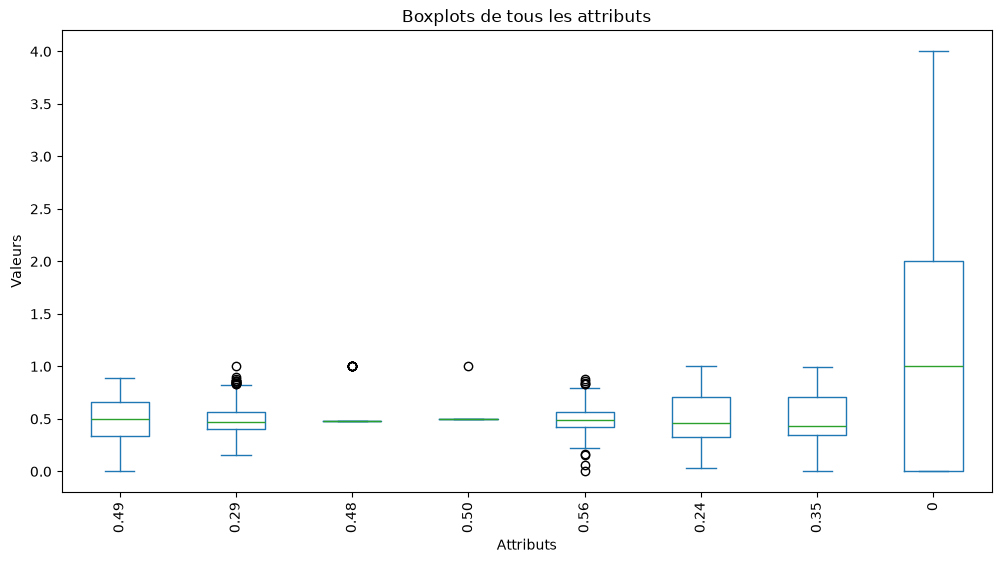

In [10]:

numeriques_ecoli.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

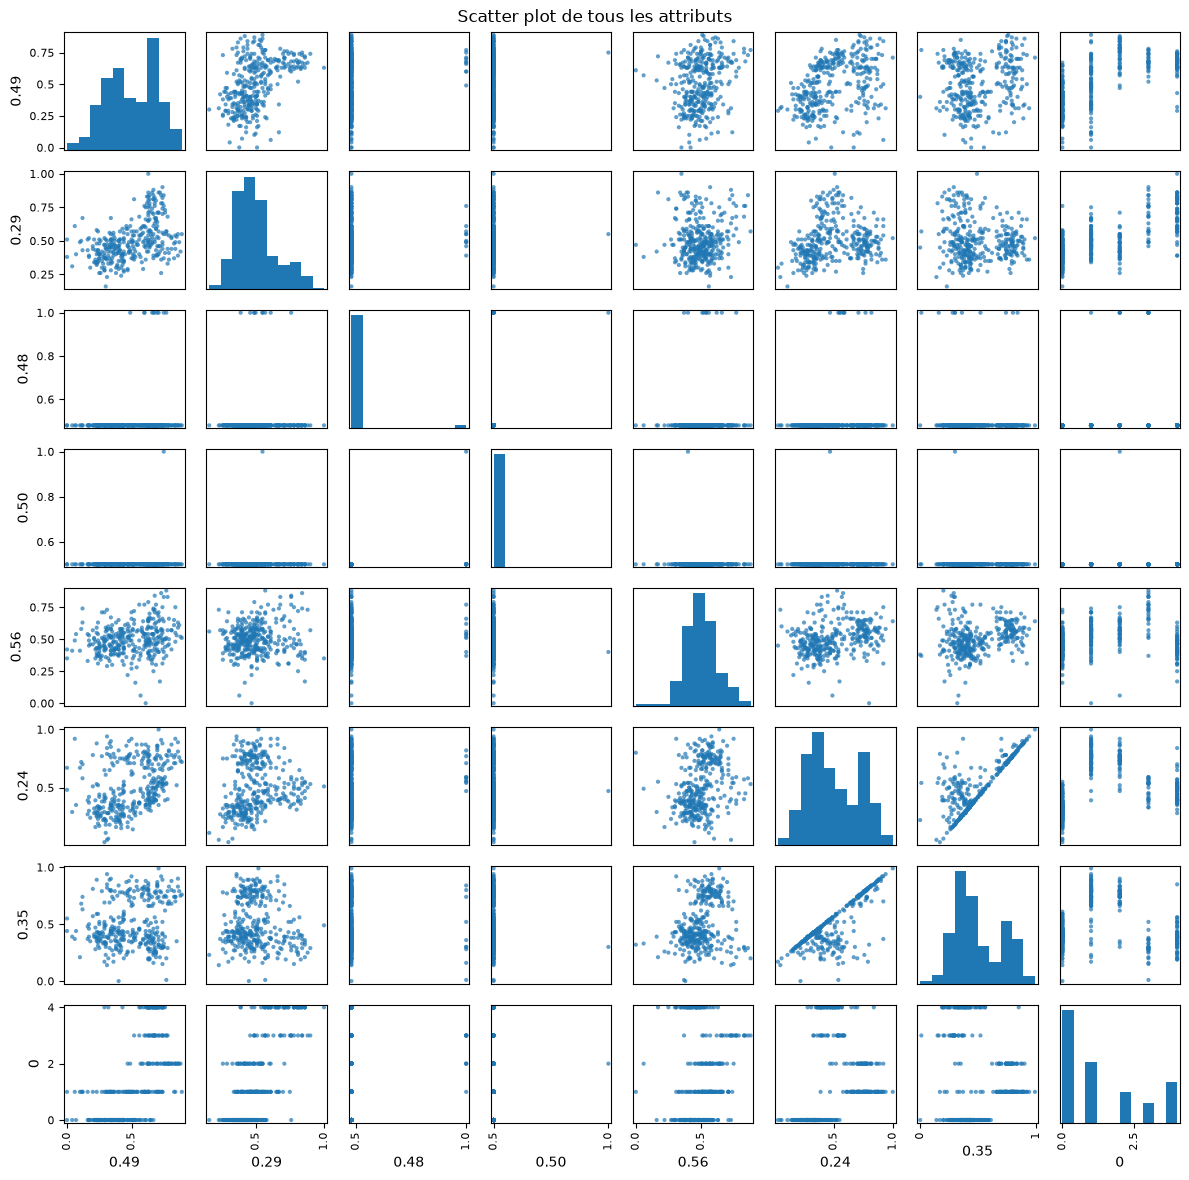

In [9]:
scatter_matrix(
    numeriques_ecoli,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- Les statistiques descriptives :

- Avec des fonctions prédéfinies


In [105]:
for col in df_ecoli.columns:
    values = df_ecoli[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_ecoli.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : 0.49
Mode : [0.63]
Moyenne : 0.500089552238806
Médiane : 0.5

Attribut : 0.29
Mode : [0.51]
Moyenne : 0.5006268656716418
Médiane : 0.47

Attribut : 0.48
Mode : [0.48]
Moyenne : 0.4955223880597015
Médiane : 0.48

Attribut : 0.50
Mode : [0.5]
Moyenne : 0.5014925373134328
Médiane : 0.5

Attribut : 0.56
Mode : [0.42]
Moyenne : 0.49985074626865666
Médiane : 0.49

Attribut : 0.24
Mode : [0.35, 0.39]
Moyenne : 0.500955223880597
Médiane : 0.46

Attribut : 0.35
Mode : [0.39]
Moyenne : 0.5001791044776119
Médiane : 0.43

Attribut : 0
Mode : [0]
Moyenne : 1.3074626865671641
Médiane : 1.0


- Manuellement

In [ ]:
for col in df_ecoli.columns:
    values = df_ecoli[col].dropna().tolist()
    frequences = {}

    for valeur in values:
        if valeur in frequences:
            frequences[valeur] += 1
        else:
            frequences[valeur] = 1

    max_frequence = max(frequences.values())

    modes = [
        valeur for valeur, frequence in frequences.items()
        if frequence == max_frequence
    ]
    #moyenne
    moyenne = sum(values) / len(values)

    #mediane
    valeurs_triees = sorted(values)
    n = len(valeurs_triees)

    if n % 2 == 0:
        mediane = (
            valeurs_triees[n // 2 - 1] +
            valeurs_triees[n // 2]
        ) / 2
    else:
        mediane = valeurs_triees[n // 2]

    print(f"\nAttribut : {col}")
    print("Mode :", modes)
    print("Moyenne :", moyenne)
    print("Médiane :", mediane)


Attribut : 0.49
Mode : [0.63]
Moyenne : 0.500089552238806
Médiane : 0.5

Attribut : 0.29
Mode : [0.51]
Moyenne : 0.5006268656716418
Médiane : 0.47

Attribut : 0.48
Mode : [0.48]
Moyenne : 0.4955223880597015
Médiane : 0.48

Attribut : 0.50
Mode : [0.5]
Moyenne : 0.5014925373134328
Médiane : 0.5

Attribut : 0.56
Mode : [0.42]
Moyenne : 0.49985074626865666
Médiane : 0.49

Attribut : 0.24
Mode : [0.35, 0.39]
Moyenne : 0.500955223880597
Médiane : 0.46

Attribut : 0.35
Mode : [0.39]
Moyenne : 0.5001791044776119
Médiane : 0.43

Attribut : 0
Mode : [0]
Moyenne : 1.3074626865671641
Médiane : 1


### 6. Gestion des valeurs manquantes:

- Identification 


In [ ]:
# Garder les noms des attributs qui contiennent des valeurs manquantes
attributs_manquants = df_ecoli.columns[df_ecoli.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [223]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_ecoli.columns:

        moyenne = df_ecoli[col].mean()
        df_ecoli[col] = df_ecoli[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df_ecoli[col].mode()
        if not modes.empty:
            mode = modes[0]
            df_ecoli[col] = df_ecoli[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df_ecoli.columns[df_ecoli.isnull().any()].tolist()
print(attributs_manquants)

[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :
- avec fonction predefinies

In [ ]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df_ecoli[numeriques_ecoli.columns] = scaler.fit_transform(numeriques_ecoli)

# Afficher le resultat
display(df_ecoli)

,0.49,0.29,0.48,0.50,0.56,0.24,0.35,0
0,0.078652,0.285714,0.0,0.0,0.613636,0.329897,0.444444,0.0
1,0.629213,0.285714,0.0,0.0,0.556818,0.350515,0.464646,0.0
2,0.662921,0.392857,0.0,0.0,0.590909,0.432990,0.363636,0.0
3,0.258427,0.190476,0.0,0.0,0.625000,0.226804,0.353535,0.0
4,0.752809,0.273810,0.0,0.0,0.409091,0.360825,0.464646,0.0
...,...,...,...,...,...,...,...,...
330,0.831461,0.476190,0.0,0.0,0.534091,0.670103,0.303030,1.0
331,0.797753,0.488095,0.0,0.0,0.545455,0.329897,0.323232,1.0
332,0.685393,0.523810,0.0,0.0,0.500000,0.371134,0.383838,1.0
333,0.662921,0.535714,0.0,0.0,0.477273,0.402062,0.373737,1.0


- Manuellement

In [ ]:
for col in numeriques_ecoli.columns:

    minimum = df_ecoli[col].min()
    maximum =  df_ecoli[col].max()

    if maximum != minimum:
        for i in range(len( df_ecoli)):
            df_ecoli.loc[i, col] = (
                ( df_ecoli.loc[i, col] - minimum) /
                (maximum - minimum)
            )

    else:
        df_ecoli[col] = 0

display(df_ecoli)

,0.49,0.29,0.48,0.50,0.56,0.24,0.35,0
0,0.078652,0.285714,0.0,0.0,0.613636,0.329897,0.444444,0.0
1,0.629213,0.285714,0.0,0.0,0.556818,0.350515,0.464646,0.0
2,0.662921,0.392857,0.0,0.0,0.590909,0.432990,0.363636,0.0
3,0.258427,0.190476,0.0,0.0,0.625000,0.226804,0.353535,0.0
4,0.752809,0.273810,0.0,0.0,0.409091,0.360825,0.464646,0.0
...,...,...,...,...,...,...,...,...
330,0.831461,0.476190,0.0,0.0,0.534091,0.670103,0.303030,1.0
331,0.797753,0.488095,0.0,0.0,0.545455,0.329897,0.323232,1.0
332,0.685393,0.523810,0.0,0.0,0.500000,0.371134,0.383838,1.0
333,0.662921,0.535714,0.0,0.0,0.477273,0.402062,0.373737,1.0




#### 7-2 Z-score :
- avec fonctions prédéfinies


In [257]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df_ecoli[numeriques_ecoli.columns] = scaler.fit_transform(numeriques_ecoli)

# Afficher le resultat
display(df_ecoli)

,0.49,0.29,0.48,0.50,0.56,0.24,0.35,0
0,-2.209744,-0.681243,-0.175412,-0.054718,0.328200,-0.701201,-0.287594,-0.893494
1,0.307812,-0.681243,-0.175412,-0.054718,-0.080525,-0.608299,-0.192015,-0.893494
2,0.461948,-0.071944,-0.175412,-0.054718,0.164710,-0.236692,-0.669911,-0.893494
3,-1.387685,-1.222843,-0.175412,-0.054718,0.409945,-1.165709,-0.717701,-0.893494
4,0.872978,-0.748943,-0.175412,-0.054718,-1.143209,-0.561848,-0.192015,-0.893494
...,...,...,...,...,...,...,...,...
330,1.232629,0.401956,-0.175412,-0.054718,-0.244015,0.831679,-0.956650,1.840027
331,1.078493,0.469656,-0.175412,-0.054718,-0.162270,-0.701201,-0.861070,1.840027
332,0.564706,0.672756,-0.175412,-0.054718,-0.489250,-0.515397,-0.574332,1.840027
333,0.461948,0.740456,-0.175412,-0.054718,-0.652739,-0.376044,-0.622122,1.840027


- Manuellement

In [258]:
for col in numeriques_ecoli.columns:

    moyenne = df_ecoli[col].mean()
    ecart_type = df_ecoli[col].std(ddof=0)

    if ecart_type != 0:
        for i in range(len(df_ecoli)):
            df_ecoli.loc[i, col] = (
                (df_ecoli.loc[i, col] - moyenne) / ecart_type
            )
    else:
        df_ecoli[col] = 0

display(df_ecoli)

,0.49,0.29,0.48,0.50,0.56,0.24,0.35,0
0,-2.209744,-0.681243,-0.175412,-0.054718,0.328200,-0.701201,-0.287594,-0.893494
1,0.307812,-0.681243,-0.175412,-0.054718,-0.080525,-0.608299,-0.192015,-0.893494
2,0.461948,-0.071944,-0.175412,-0.054718,0.164710,-0.236692,-0.669911,-0.893494
3,-1.387685,-1.222843,-0.175412,-0.054718,0.409945,-1.165709,-0.717701,-0.893494
4,0.872978,-0.748943,-0.175412,-0.054718,-1.143209,-0.561848,-0.192015,-0.893494
...,...,...,...,...,...,...,...,...
330,1.232629,0.401956,-0.175412,-0.054718,-0.244015,0.831679,-0.956650,1.840027
331,1.078493,0.469656,-0.175412,-0.054718,-0.162270,-0.701201,-0.861070,1.840027
332,0.564706,0.672756,-0.175412,-0.054718,-0.489250,-0.515397,-0.574332,1.840027
333,0.461948,0.740456,-0.175412,-0.054718,-0.652739,-0.376044,-0.622122,1.840027


# Dataset **diabetes.arff**

###  1-lire et afficher le dataset

In [2]:

data, meta= arff.loadarff("datasets/diabetes.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)


,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,tested_positive
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,tested_negative
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,tested_positive
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,tested_negative
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,tested_positive
...,...,...,...,...,...,...,...,...,...
763,10.0,101.0,76.0,48.0,180.0,32.9,0.171,63.0,tested_negative
764,2.0,122.0,70.0,27.0,0.0,36.8,0.340,27.0,tested_negative
765,5.0,121.0,72.0,23.0,112.0,26.2,0.245,30.0,tested_negative
766,1.0,126.0,60.0,0.0,0.0,30.1,0.349,47.0,tested_positive


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [97]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 768


- Nombre des attributs (colonnes).

In [98]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 9


- Noms des attributs (colonnes).

In [99]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['preg', 'plas', 'pres', 'skin', 'insu', 'mass', 'pedi', 'age', 'class']


- Type de chaque attribut:

In [100]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
preg     float64
plas     float64
pres     float64
skin     float64
insu     float64
mass     float64
pedi     float64
age      float64
class        str
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

il faut premierement selectionner les valeurs numerique du dataset afin de calculer les 5 nombres clés

In [3]:
numeriques_df = df.select_dtypes(include=np.number)

**Remarque**:pour les attributs qui ont un type string et qui ne sont pas des valeurs numiques on ne va pas calculer leur 5 nombres cles

#### En utilisant des fonctions predefinies

In [27]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)
   



Attribut: preg
Minimum: 0.0
Maximum: 17.0
Q1: 1.0
Median: 3.0
Q3: 6.0

Attribut: plas
Minimum: 0.0
Maximum: 199.0
Q1: 99.0
Median: 117.0
Q3: 140.25

Attribut: pres
Minimum: 0.0
Maximum: 122.0
Q1: 62.0
Median: 72.0
Q3: 80.0

Attribut: skin
Minimum: 0.0
Maximum: 99.0
Q1: 0.0
Median: 23.0
Q3: 32.0

Attribut: insu
Minimum: 0.0
Maximum: 846.0
Q1: 0.0
Median: 30.5
Q3: 127.25

Attribut: mass
Minimum: 0.0
Maximum: 67.1
Q1: 27.3
Median: 32.0
Q3: 36.6

Attribut: pedi
Minimum: 0.078
Maximum: 2.42
Q1: 0.24375
Median: 0.3725
Q3: 0.62625

Attribut: age
Minimum: 21.0
Maximum: 81.0
Q1: 24.0
Median: 29.0
Q3: 41.0


### 4-Visualiser la distribution des données :
- les boxplot

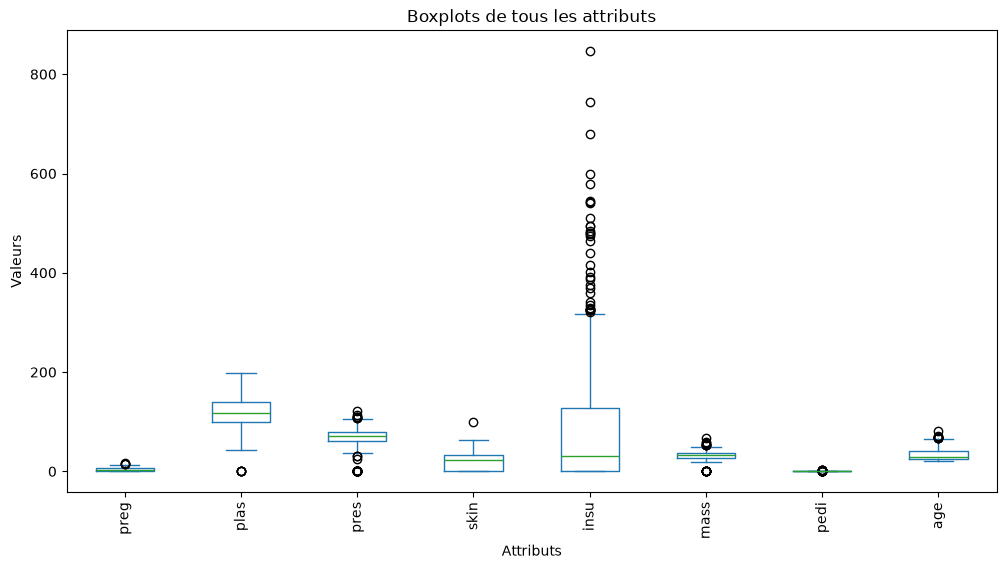

In [71]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

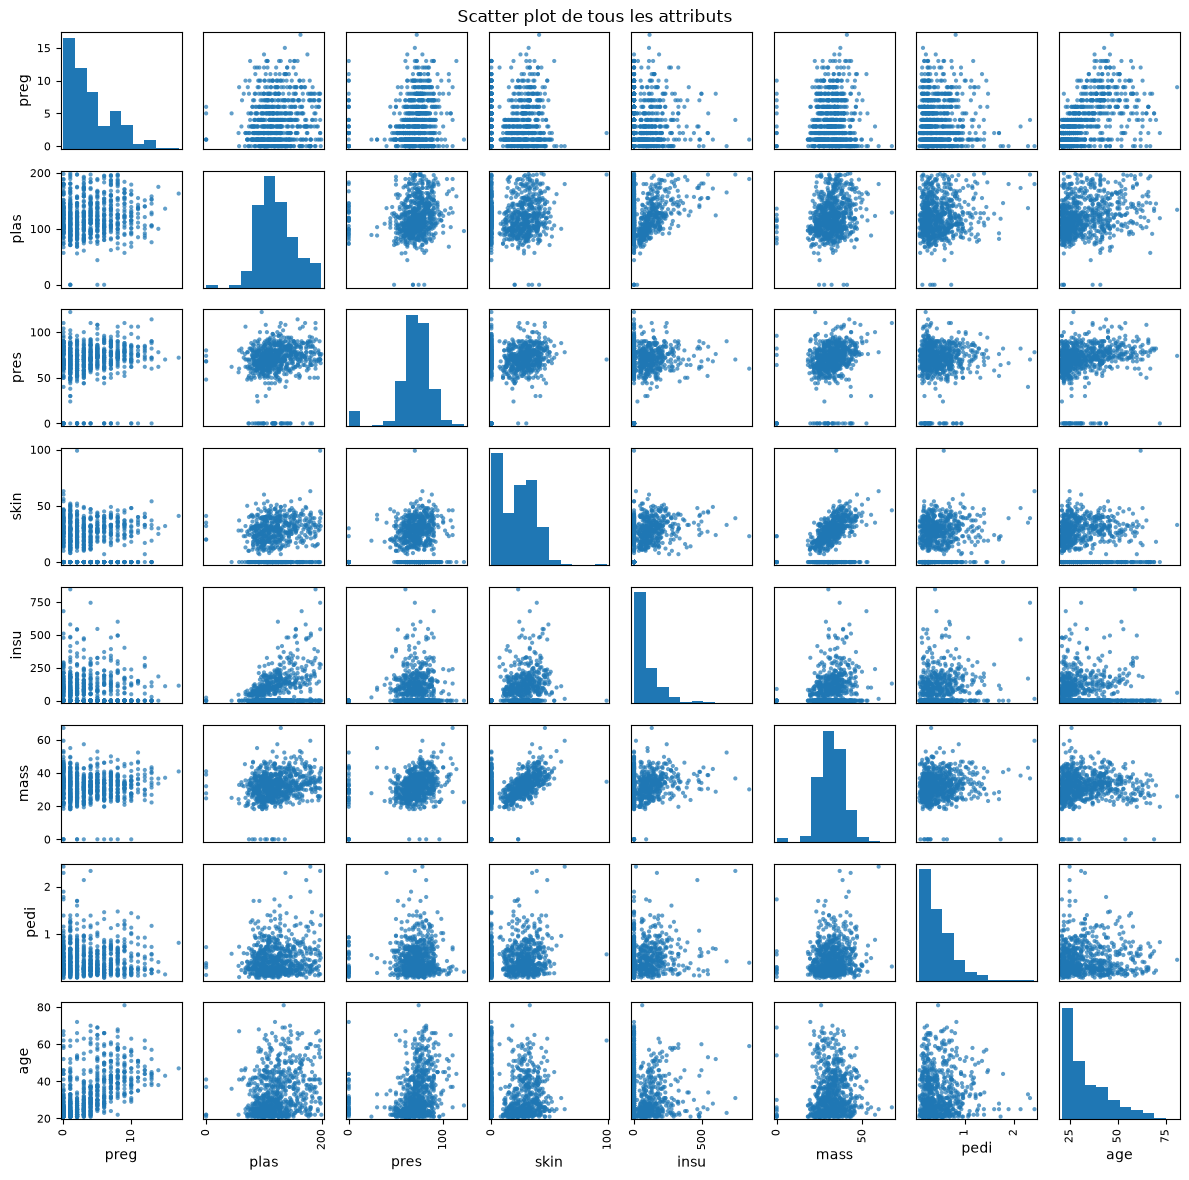

In [72]:
scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [160]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : preg
Mode : [1.0]
Moyenne : 3.8450520833333335
Médiane : 3.0

Attribut : plas
Mode : [99.0, 100.0]
Moyenne : 120.89453125
Médiane : 117.0

Attribut : pres
Mode : [70.0]
Moyenne : 69.10546875
Médiane : 72.0

Attribut : skin
Mode : [0.0]
Moyenne : 20.536458333333332
Médiane : 23.0

Attribut : insu
Mode : [0.0]
Moyenne : 79.79947916666667
Médiane : 30.5

Attribut : mass
Mode : [32.0]
Moyenne : 31.992578124999998
Médiane : 32.0

Attribut : pedi
Mode : [0.254, 0.258]
Moyenne : 0.47187630208333325
Médiane : 0.3725

Attribut : age
Mode : [22.0]
Moyenne : 33.240885416666664
Médiane : 29.0

Attribut : class
Mode : ['tested_negative']


### 6. Gestion des valeurs manquantes:

- Identification:

In [226]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [ ]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [ ]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

display(df)

,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,...,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,2.0,0.0,0.002428,0.574074,0.233766,0.227273,3.0,3.0,1.0,2.0,...,0.423077,0.059510,2.0,NaN,2.0,2,11300,0,0,2
1,1.0,0.0,0.003414,0.703704,0.376623,0.136364,3.0,1.0,4.0,1.0,...,0.519231,0.953326,2.0,0.19,3.0,2,2208,0,0,2
2,2.0,0.0,0.002477,0.537037,0.064935,0.181818,1.0,1.0,3.0,1.0,...,0.192308,0.039673,2.0,NaN,1.0,2,0,0,0,1
3,1.0,1.0,0.996821,0.685185,0.870130,0.863636,4.0,1.0,6.0,2.0,...,0.480769,0.045508,3.0,0.52,2.0,1,2208,0,0,1
4,2.0,0.0,0.002461,0.351852,0.480519,0.306818,3.0,1.0,6.0,2.0,...,0.980769,0.047841,2.0,NaN,2.0,2,4300,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,1.0,0.0,0.003219,NaN,0.584416,0.704545,4.0,1.0,4.0,2.0,...,0.615385,0.719953,2.0,NaN,3.0,2,3205,0,0,2
296,2.0,0.0,0.001927,0.333333,0.272727,0.181818,3.0,2.0,4.0,2.0,...,0.403846,NaN,3.0,0.32,3.0,1,2208,0,0,1
297,1.0,0.0,0.002279,0.388889,0.272727,0.250000,4.0,3.0,4.0,1.0,...,0.711538,0.040840,2.0,NaN,2.0,1,3205,0,0,2
298,1.0,0.0,0.002535,0.203704,0.454545,0.181818,3.0,3.0,3.0,1.0,...,0.519231,0.031505,3.0,0.33,1.0,1,2208,0,0,1


#### 7-2 Z-score :

In [4]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,0.639947,0.848324,0.149641,0.907270,-0.692891,0.204013,0.468492,1.425995,tested_positive
1,-0.844885,-1.123396,-0.160546,0.530902,-0.692891,-0.684422,-0.365061,-0.190672,tested_negative
2,1.233880,1.943724,-0.263941,-1.288212,-0.692891,-1.103255,0.604397,-0.105584,tested_positive
3,-0.844885,-0.998208,-0.160546,0.154533,0.123302,-0.494043,-0.920763,-1.041549,tested_negative
4,-1.141852,0.504055,-1.504687,0.907270,0.765836,1.409746,5.484909,-0.020496,tested_positive
...,...,...,...,...,...,...,...,...,...
763,1.827813,-0.622642,0.356432,1.722735,0.870031,0.115169,-0.908682,2.532136,tested_negative
764,-0.547919,0.034598,0.046245,0.405445,-0.692891,0.610154,-0.398282,-0.531023,tested_negative
765,0.342981,0.003301,0.149641,0.154533,0.279594,-0.735190,-0.685193,-0.275760,tested_negative
766,-0.844885,0.159787,-0.470732,-1.288212,-0.692891,-0.240205,-0.371101,1.170732,tested_positive


# Dataset **breast.csv**

###  1-lire et afficher le dataset

In [13]:
df = pd.read_csv("datasets/breast.csv")
print("Aperçu du dataset  :")
display(df)

Aperçu du dataset  :


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.015870,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.013400,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.020580,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.018670,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.018850,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,14.87,20.21,96.12,680.9,0.09587,0.08345,0.06824,0.04951,0.1487,0.05748,0.2323,1.6360,1.596,21.84,0.005415,0.01371,0.02153,0.011830,0
496,12.65,18.17,82.69,485.6,0.10760,0.13340,0.08017,0.05074,0.1641,0.06854,0.2324,0.6332,1.696,18.40,0.005704,0.02502,0.02636,0.010320,0
497,12.47,17.31,80.45,480.1,0.08928,0.07630,0.03609,0.02369,0.1526,0.06046,0.1532,0.7810,1.253,11.91,0.003796,0.01371,0.01346,0.007096,0
498,18.49,17.52,121.30,1068.0,0.10120,0.13170,0.14910,0.09183,0.1832,0.06697,0.7923,1.0450,4.851,95.77,0.007974,0.03214,0.04435,0.015730,1


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [36]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 500


- Nombre des attributs (colonnes).


In [37]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 19


- Noms des attributs (colonnes).

In [38]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'diagnosis']


- Type de chaque attribut:

In [39]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
radius_mean               float64
texture_mean              float64
perimeter_mean            float64
area_mean                 float64
smoothness_mean           float64
compactness_mean          float64
concavity_mean            float64
concave_points_mean       float64
symmetry_mean             float64
fractal_dimension_mean    float64
radius_se                 float64
texture_se                float64
perimeter_se              float64
area_se                   float64
smoothness_se             float64
compactness_se            float64
concavity_se              float64
concave_points_se         float64
diagnosis                   int64
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

il faut premierement selectionner les valeurs numerique du dataset afin de calculer les 5 nombres clés

In [14]:
numeriques_df = df.select_dtypes(include=np.number)

In [15]:
cat_colon= ["diagnosis"]

numeriques_df = numeriques_df.drop(
    columns=cat_colon
    )

####  En utilisant des fonctions prédéfinies.

In [5]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)
   



Attribut: radius_mean
Minimum: 6.981
Maximum: 28.11
Q1: 11.807500000000001
Median: 13.434999999999999
Q3: 16.115

Attribut: texture_mean
Minimum: 9.71
Maximum: 39.28
Q1: 16.07
Median: 18.68
Q3: 21.5625

Attribut: perimeter_mean
Minimum: 43.79
Maximum: 188.5
Q1: 75.995
Median: 86.735
Q3: 106.225

Attribut: area_mean
Minimum: 143.5
Maximum: 2501.0
Q1: 430.55
Median: 556.1500000000001
Q3: 800.775

Attribut: smoothness_mean
Minimum: 0.06251
Maximum: 0.1447
Q1: 0.0859925
Median: 0.095825
Q3: 0.1051

Attribut: compactness_mean
Minimum: 0.01938
Maximum: 0.3454
Q1: 0.0636225
Median: 0.09128
Q3: 0.1305

Attribut: concavity_mean
Minimum: 0.0
Maximum: 0.4268
Q1: 0.028885
Median: 0.064315
Q3: 0.13215

Attribut: concave_points_mean
Minimum: 0.0
Maximum: 0.2012
Q1: 0.020245
Median: 0.03387
Q3: 0.07492750000000001

Attribut: symmetry_mean
Minimum: 0.1167
Maximum: 0.304
Q1: 0.161875
Median: 0.17955
Q3: 0.195625

Attribut: fractal_dimension_mean
Minimum: 0.04996
Maximum: 0.09744
Q1: 0.0576075
Median: 

### 4-Visualiser la distribution des données :
- les boxplots

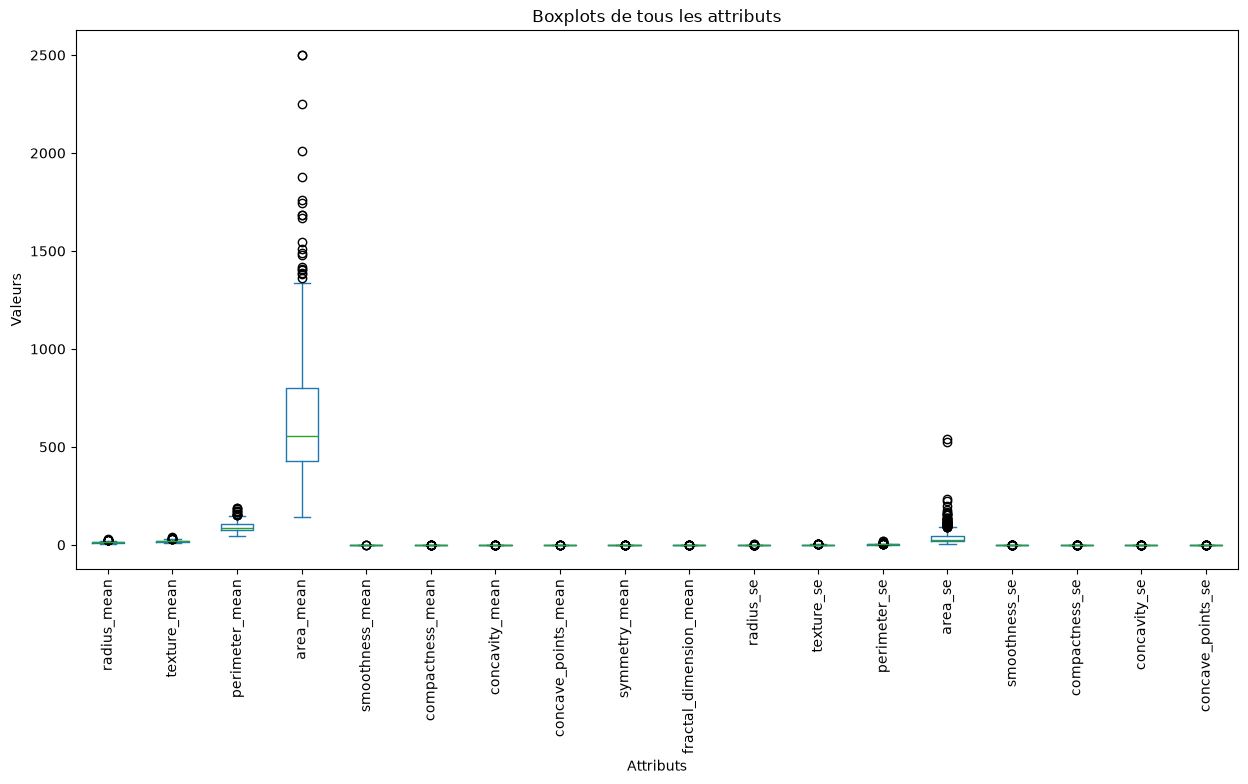

In [16]:

numeriques_df.plot(kind="box", figsize=(15, 7))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

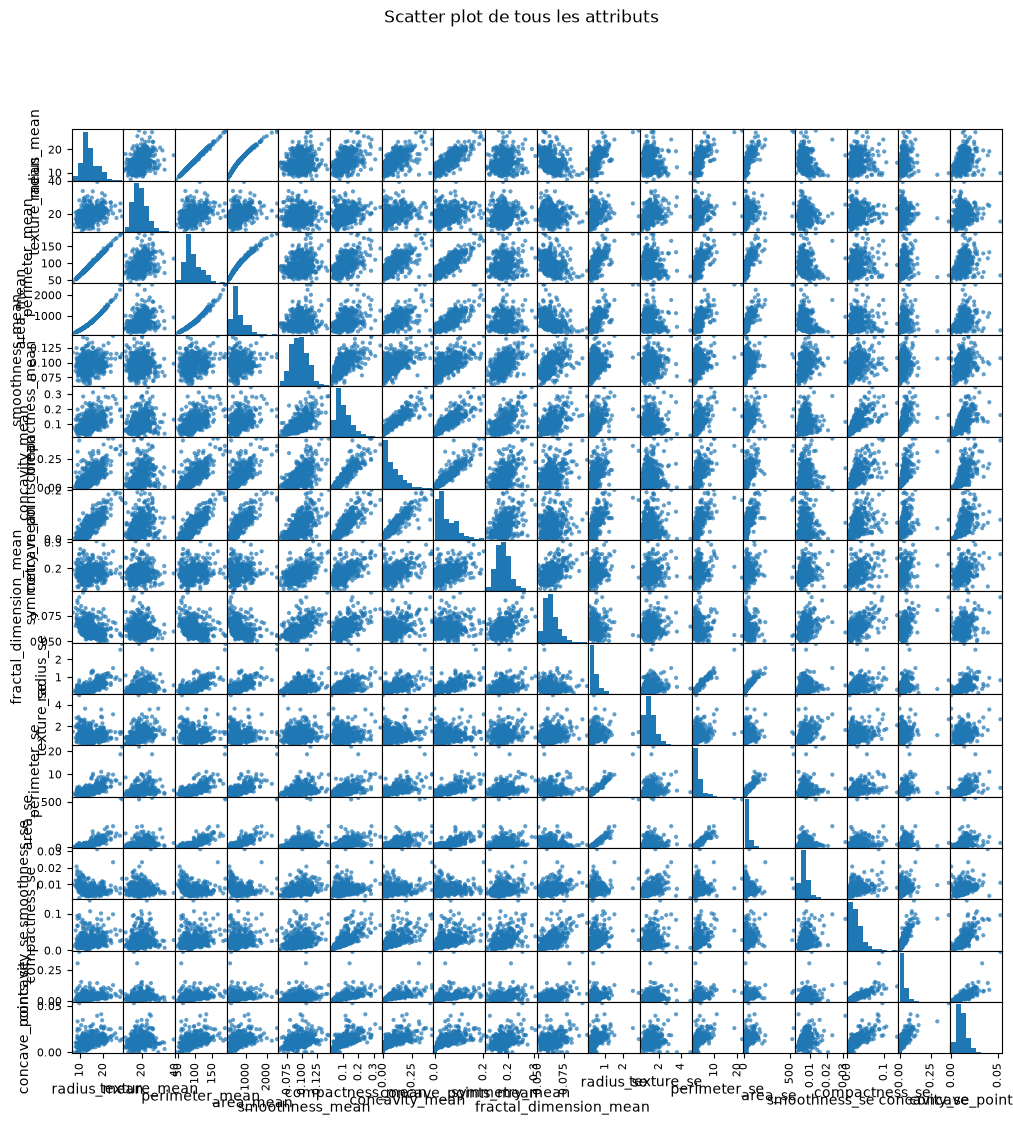

In [17]:
scatter_matrix(numeriques_df,figsize=(12, 12),alpha=0.7)
plt.suptitle("Scatter plot de tous les attributs")

plt.show()

### 4- statistiques descriptives :

In [18]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : radius_mean
Mode : [11.6, 11.71, 11.89, 12.18, 12.34, 12.46, 12.89, 13.0, 13.05, 13.17, 13.85]
Moyenne : 14.224205999999999
Médiane : 13.434999999999999

Attribut : texture_mean
Mode : [14.93, 16.84, 16.85, 17.46, 18.9]
Moyenne : 19.08632
Médiane : 18.68

Attribut : perimeter_mean
Mode : [82.61]
Moyenne : 92.60661999999999
Médiane : 86.735

Attribut : area_mean
Mode : [512.2]
Moyenne : 662.8448000000001
Médiane : 556.1500000000001

Attribut : smoothness_mean
Mode : [0.1007]
Moyenne : 0.09597836000000001
Médiane : 0.095825

Attribut : compactness_mean
Mode : [0.1147, 0.1206]
Moyenne : 0.10394772000000001
Médiane : 0.09128

Attribut : concavity_mean
Mode : [0.0]
Moyenne : 0.08994091739999999
Médiane : 0.064315

Attribut : concave_points_mean
Mode : [0.0]
Moyenne : 0.04944579999999999
Médiane : 0.03387

Attribut : symmetry_mean
Mode : [0.1601, 0.1717, 0.1769, 0.1893]
Moyenne : 0.18137
Médiane : 0.17955

Attribut : fractal_dimension_mean
Mode : [0.05667, 0.05907, 0.05913, 0.061

### 6. Gestion des valeurs manquantes:

- Identification:

In [19]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [20]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [21]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,diagnosis
0,0.521037,0.022658,0.545989,0.363733,0.680010,0.792037,0.703140,0.731113,0.668446,0.605518,0.356147,0.120469,0.369034,0.273811,0.159296,0.351398,0.135682,0.300625,1
1,0.643144,0.272574,0.615783,0.501591,0.270471,0.181768,0.203608,0.348757,0.344367,0.141323,0.156437,0.082589,0.124440,0.125660,0.119387,0.081323,0.046970,0.253836,1
2,0.601496,0.390260,0.595743,0.449417,0.572941,0.431017,0.462512,0.635686,0.481580,0.211247,0.229622,0.094303,0.180370,0.162922,0.150831,0.283955,0.096768,0.389847,1
3,0.210090,0.360839,0.233501,0.102906,0.973233,0.811361,0.565604,0.522863,0.763481,1.000000,0.139091,0.175875,0.126655,0.038155,0.251453,0.543215,0.142955,0.353665,1
4,0.629893,0.156578,0.630986,0.489290,0.459788,0.347893,0.463918,0.518390,0.342766,0.186816,0.233822,0.093065,0.220563,0.163688,0.332359,0.167918,0.143636,0.357075,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0.373373,0.355090,0.361620,0.227953,0.405889,0.196522,0.159888,0.246074,0.170849,0.158382,0.043744,0.281957,0.039533,0.028088,0.125846,0.086055,0.054369,0.224095,0
496,0.268304,0.286101,0.268813,0.145111,0.548607,0.349733,0.187840,0.252187,0.253070,0.391323,0.043781,0.060334,0.044244,0.021662,0.135670,0.170998,0.066566,0.195492,0
497,0.259785,0.257017,0.253334,0.142778,0.325709,0.174591,0.084560,0.117744,0.191671,0.221146,0.015100,0.092999,0.023371,0.009541,0.070809,0.086055,0.033990,0.134419,0
498,0.544702,0.264119,0.535623,0.392153,0.470739,0.344519,0.349344,0.456412,0.355045,0.358256,0.246533,0.151344,0.192904,0.166172,0.212836,0.224472,0.111995,0.297973,1


#### 7-2 Z-score :

In [22]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,diagnosis
0,1.084203,-2.092526,1.260185,0.968905,1.642284,3.273826,2.621146,2.514512,2.186130,2.363520,2.431939,-0.548182,2.773660,2.406884,-0.181684,1.273042,0.689477,0.656891,1
1,1.827006,-0.316372,1.681730,1.900116,-0.823159,-0.477121,-0.037927,0.533630,-0.006140,-0.849484,0.474716,-0.866924,0.244343,0.706411,-0.580826,-0.677640,-0.433062,0.258702,1
2,1.573646,0.520031,1.560692,1.547688,0.997724,1.054855,1.340251,2.020129,0.922053,-0.365492,1.191951,-0.768363,0.822709,1.134102,-0.266340,0.785914,0.197068,1.416192,1
3,-0.807354,0.310930,-0.627168,-0.792948,3.407500,3.392599,1.889028,1.435623,2.829003,5.093991,0.304723,-0.081970,0.267243,-0.297966,0.740015,2.658482,0.781504,1.108280,1
4,1.746391,-1.140757,1.773552,1.817023,0.316541,0.543945,1.347734,1.412449,-0.016975,-0.534598,1.233118,-0.778777,1.238334,1.142891,1.549180,-0.052185,0.790132,1.137298,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0.185929,0.270072,0.146638,0.051733,-0.007937,-0.386439,-0.270658,0.001653,-1.179925,-0.731402,-0.629704,0.810657,-0.633682,-0.413518,-0.516229,-0.643465,-0.339437,0.005602,0
496,-0.453227,-0.220233,-0.413891,-0.507854,0.851233,0.555257,-0.121865,0.033325,-0.623731,0.880932,-0.629349,-1.054190,-0.584957,-0.487265,-0.417973,-0.029944,-0.185100,-0.237826,0
497,-0.505050,-0.426931,-0.507382,-0.523613,-0.490625,-0.521236,-0.671639,-0.663190,-1.039071,-0.296975,-0.910423,-0.779335,-0.800809,-0.626398,-1.066665,-0.643465,-0.597305,-0.757568,0
498,1.228157,-0.376458,1.197579,1.160878,0.382462,0.523207,0.737844,1.091357,0.066093,0.652056,1.357685,-0.288390,0.952318,1.171404,0.353792,0.356286,0.389750,0.634322,1


# Dataset **heart.csv**

###  1-lire et afficher le dataset

In [23]:
df = pd.read_csv("datasets/heart.csv")
print("Aperçu du dataset :")
display(df)

Aperçu du dataset :


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,60,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,35,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,55,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,56,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284,60,1,0,140,207,0,0,138,1,1.9,2,1,3,0
285,46,1,0,140,311,0,1,120,1,1.8,1,2,3,0
286,59,1,3,134,204,0,1,162,0,0.8,2,2,2,0
287,54,1,1,154,232,0,0,164,0,0.0,2,1,2,0


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [169]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 289


- Nombre des attributs (colonnes).

In [170]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 14


- Noms des attributs (colonnes).

In [171]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall', 'output']


- Type de chaque attribut:

In [172]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
age           int64
sex           int64
cp            int64
trtbps        int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exng          int64
oldpeak     float64
slp           int64
caa           int64
thall         int64
output        int64
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

 **Selectionner les valeurs numerique**

In [24]:
numeriques_df = df.select_dtypes(include=np.number)

**Exclure les colonnes catégorielles**

In [25]:
cat_colon= ["sex", "cp", "fbs", "exng","restecg","slp","caa","thall","output"]
numeriques_df = numeriques_df.drop(
    columns=cat_colon
    )

#### En utilisant des fonctions prédéfinies

In [184]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)


Attribut: age
Minimum: 29
Maximum: 77
Q1: 47.0
Median: 54.0
Q3: 60.0

Attribut: trtbps
Minimum: 94
Maximum: 200
Q1: 120.0
Median: 130.0
Q3: 140.0

Attribut: chol
Minimum: 126
Maximum: 564
Q1: 212.0
Median: 243.0
Q3: 276.0

Attribut: thalachh
Minimum: 71
Maximum: 202
Q1: 136.0
Median: 154.0
Q3: 168.0

Attribut: oldpeak
Minimum: 0.0
Maximum: 6.2
Q1: 0.0
Median: 0.6
Q3: 1.6


### 4-Visualiser la distribution des données :
- les boxplot

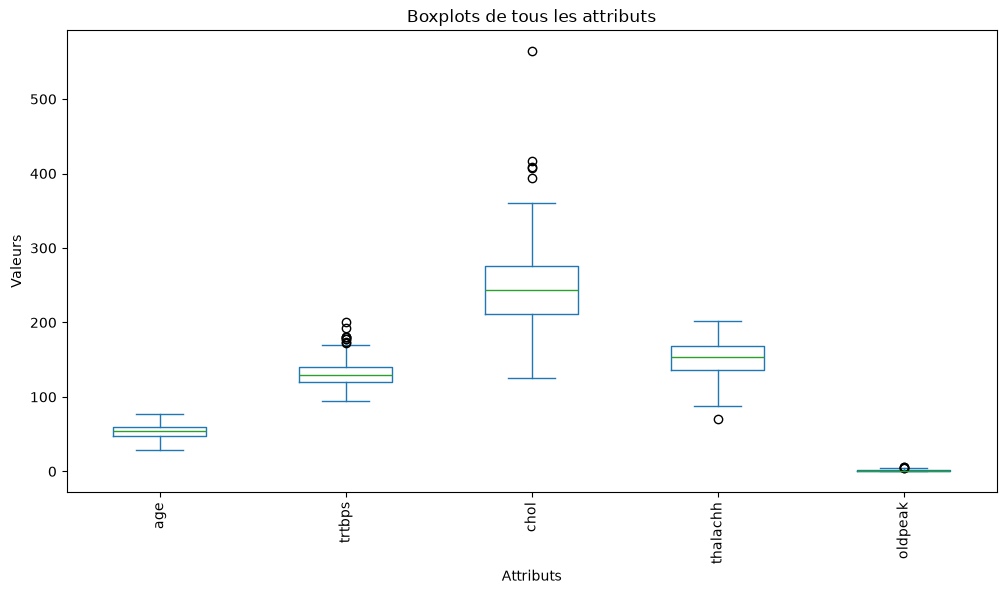

In [185]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

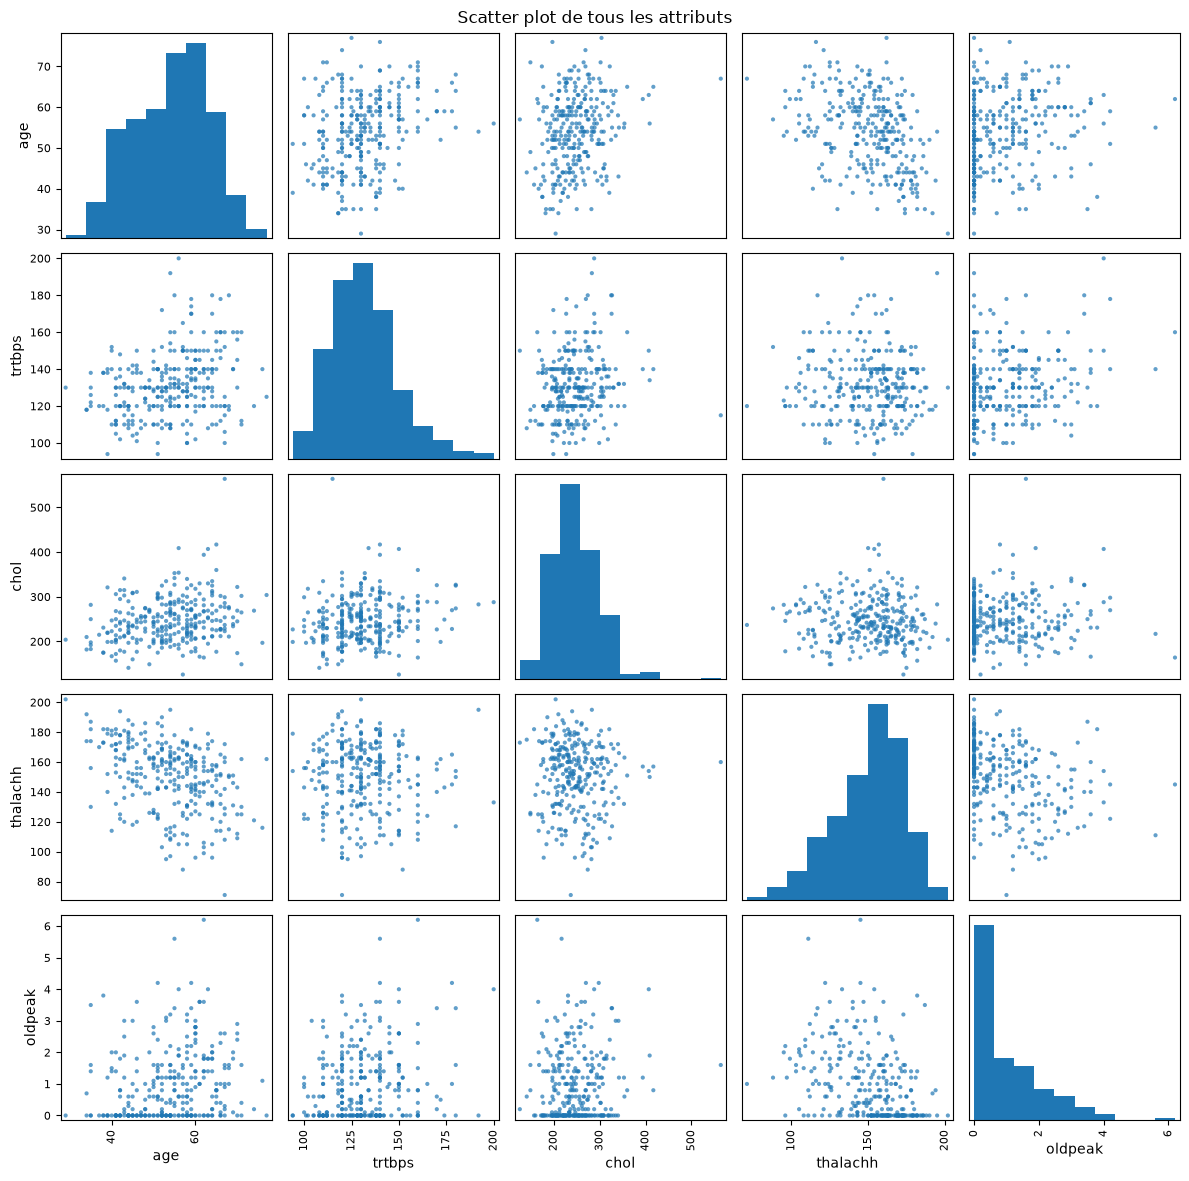

In [186]:
scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [32]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : age
Mode : [54]
Moyenne : 54.01038062283737
Médiane : 54.0

Attribut : sex
Mode : [1]

Attribut : cp
Mode : [0]

Attribut : trtbps
Mode : [120]
Moyenne : 131.37716262975778
Médiane : 130.0

Attribut : chol
Mode : [204, 234]
Moyenne : 247.96193771626298
Médiane : 243.0

Attribut : fbs
Mode : [0]

Attribut : restecg
Mode : [1]

Attribut : thalachh
Mode : [162]
Moyenne : 150.2318339100346
Médiane : 154.0

Attribut : exng
Mode : [0]

Attribut : oldpeak
Mode : [0.0]
Moyenne : 1.0076124567474047
Médiane : 0.6

Attribut : slp
Mode : [2]

Attribut : caa
Mode : [0]

Attribut : thall
Mode : [2]

Attribut : output
Mode : [1]


### 6. Gestion des valeurs manquantes:

- Identification:

In [26]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [27]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [28]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,0.645833,1,3,0.481132,0.244292,1,0,0.603053,0,0.370968,0,0,1,1
1,0.125000,1,2,0.339623,0.283105,0,1,0.885496,0,0.564516,0,0,2,1
2,0.250000,0,1,0.339623,0.178082,0,0,0.770992,0,0.225806,2,0,2,1
3,0.541667,1,1,0.245283,0.251142,0,1,0.816794,0,0.129032,2,0,2,1
4,0.562500,0,0,0.245283,0.520548,0,1,0.702290,1,0.096774,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284,0.645833,1,0,0.433962,0.184932,0,0,0.511450,1,0.306452,2,1,3,0
285,0.354167,1,0,0.433962,0.422374,0,1,0.374046,1,0.290323,1,2,3,0
286,0.625000,1,3,0.377358,0.178082,0,1,0.694656,0,0.129032,2,2,2,0
287,0.520833,1,1,0.566038,0.242009,0,0,0.709924,0,0.000000,2,1,2,0


#### 7-2 Z-score :

In [13]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,0.657008,1,3,0.778978,-0.290484,1,0,-0.010141,0,1.142161,0,0,1,1
1,-2.085271,1,2,-0.078749,0.039569,0,1,1.608406,0,2.202673,0,0,2,1
2,-1.427124,0,1,-0.078749,-0.853516,0,0,0.952238,0,0.346776,2,0,2,1
3,0.108553,1,1,-0.650566,-0.232240,0,1,1.214706,0,-0.183480,2,0,2,1
4,0.218244,0,0,-0.650566,2.058717,0,1,0.558538,1,-0.360232,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284,0.657008,1,0,0.493069,-0.795271,0,0,-0.535076,1,0.788657,2,1,3,0
285,-0.878668,1,0,0.493069,1.223877,0,1,-1.322478,1,0.700281,1,2,3,0
286,0.547317,1,3,0.149978,-0.853516,0,1,0.514793,0,-0.183480,2,2,2,0
287,-0.001139,1,1,1.293613,-0.309899,0,0,0.602282,0,-0.890488,2,1,2,0


# Dataset **hepatitis.csv**

###  1-lire et afficher le dataset

In [29]:
df = pd.read_csv("datasets/hepatitis.csv")
print("Aperçu du dataset :")
display(df)

Aperçu du dataset :


,class,age,sex,steroid,antivirals,fatigue,malaise,anorexia,liver_big,liver_firm,spleen_palable,spiders,ascites,varices,bilirubin,alk_phosphate,sgot,albumin,protime,histology
0,2,30,2,1,2,2,2,2,1,2,2,2,2,2,1.0,85,18,4.0,61,1
1,2,50,1,1,2,1,2,2,1,2,2,2,2,2,0.9,135,42,3.5,61,1
2,2,78,1,2,2,1,2,2,2,2,2,2,2,2,0.7,96,32,4.0,61,1
3,2,34,1,2,2,2,2,2,2,2,2,2,2,2,1.0,105,200,4.0,61,1
4,2,34,1,2,2,2,2,2,2,2,2,2,2,2,0.9,95,28,4.0,75,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,1,46,1,2,2,1,1,1,2,1,2,1,1,1,7.6,105,242,3.3,50,2
138,2,44,1,2,2,1,2,2,2,1,2,2,2,2,0.9,126,142,4.3,61,2
139,2,61,1,1,2,1,1,2,1,2,2,1,2,2,0.8,75,20,4.1,61,2
140,2,53,2,1,2,1,2,2,2,2,1,1,2,1,1.5,81,19,4.1,48,2


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [218]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 142


- Nombre des attributs (colonnes).

In [219]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 20


- Noms des attributs (colonnes).

In [220]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['class', 'age', 'sex', 'steroid', 'antivirals', 'fatigue', 'malaise', 'anorexia', 'liver_big', 'liver_firm', 'spleen_palable', 'spiders', 'ascites', 'varices', 'bilirubin', 'alk_phosphate', 'sgot', 'albumin', 'protime', 'histology']


- Type de chaque attribut:

In [221]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
class               int64
age                 int64
sex                 int64
steroid             int64
antivirals          int64
fatigue             int64
malaise             int64
anorexia            int64
liver_big           int64
liver_firm          int64
spleen_palable      int64
spiders             int64
ascites             int64
varices             int64
bilirubin         float64
alk_phosphate       int64
sgot                int64
albumin           float64
protime             int64
histology           int64
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

**selectionner les valeurs numeriques**

In [30]:
numeriques_df = df.select_dtypes(include=np.number)

**Exclure les colonnes catégorielles**

In [31]:
cat_colon= ["class","sex","steroid","antivirals","fatigue","malaise","anorexia","liver_firm","liver_firm","spleen_palable","spiders","ascites","varices","histology"]

numeriques_df = numeriques_df.drop(
    columns=cat_colon
    )

####  En utilisant des fonctions prédéfinies.

In [193]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)


Attribut: age
Minimum: 7
Maximum: 78
Q1: 32.0
Median: 39.0
Q3: 50.0

Attribut: liver_big
Minimum: 1
Maximum: 2
Q1: 2.0
Median: 2.0
Q3: 2.0

Attribut: bilirubin
Minimum: 0.3
Maximum: 8.0
Q1: 0.7
Median: 1.0
Q3: 1.48

Attribut: alk_phosphate
Minimum: 26
Maximum: 295
Q1: 78.5
Median: 100.0
Q3: 119.75

Attribut: sgot
Minimum: 14
Maximum: 648
Q1: 32.25
Median: 58.0
Q3: 99.5

Attribut: albumin
Minimum: 2.1
Maximum: 6.4
Q1: 3.5
Median: 3.9
Q3: 4.2

Attribut: protime
Minimum: 0
Maximum: 100
Q1: 56.25
Median: 61.0
Q3: 66.0


### 4-Visualiser la distribution des données :
- les boxplot

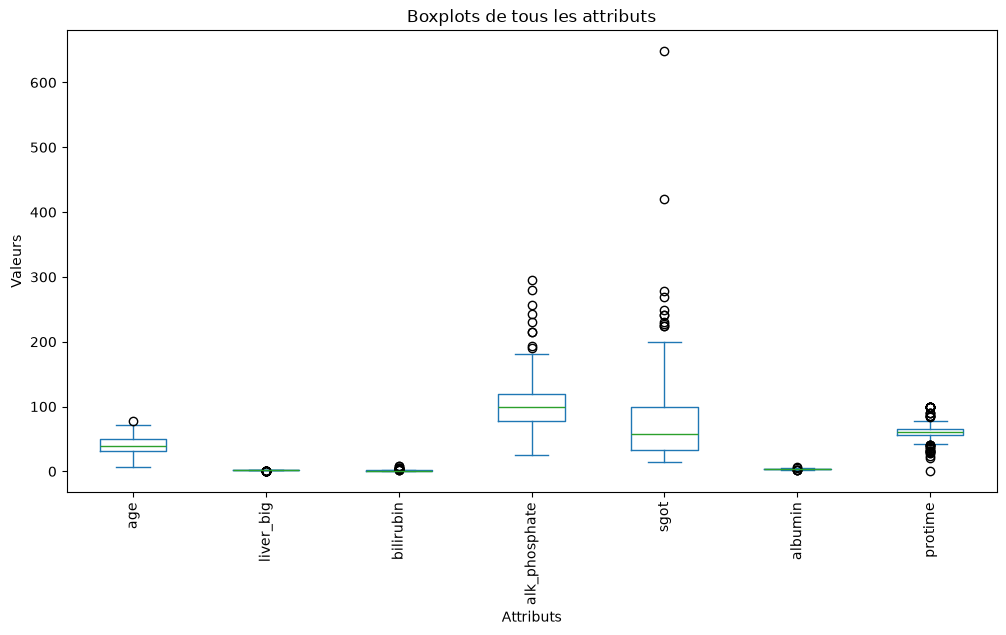

In [194]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

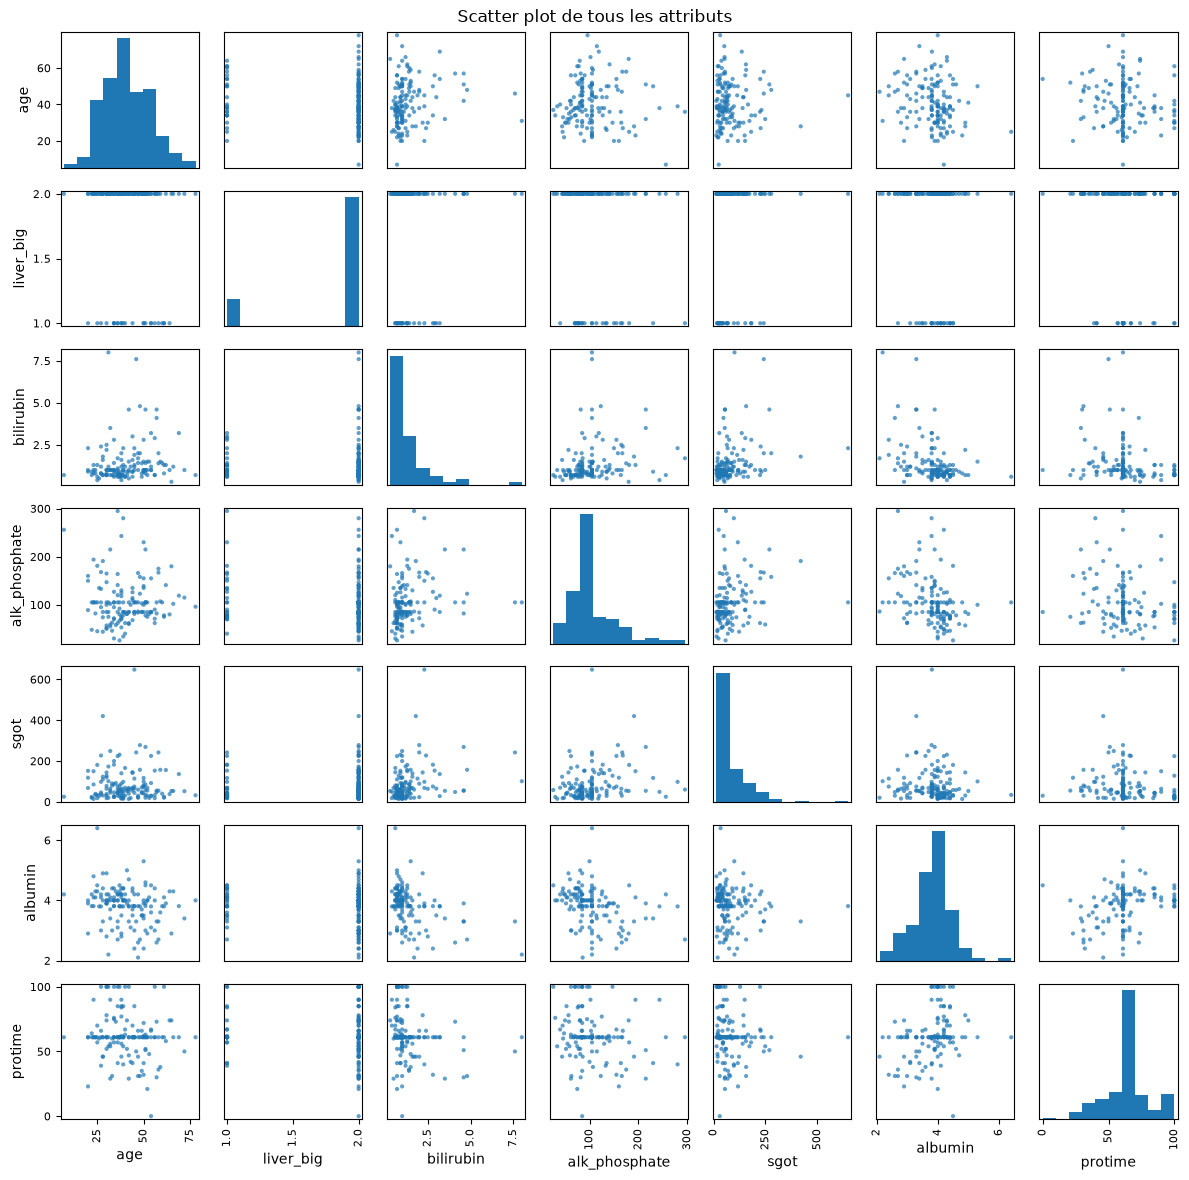

In [195]:
scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [36]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : class
Mode : [2]

Attribut : age
Mode : [30, 38]
Moyenne : 40.816901408450704
Médiane : 39.0

Attribut : sex
Mode : [1]

Attribut : steroid
Mode : [2]

Attribut : antivirals
Mode : [2]

Attribut : fatigue
Mode : [1]

Attribut : malaise
Mode : [2]

Attribut : anorexia
Mode : [2]

Attribut : liver_big
Mode : [2]
Moyenne : 1.823943661971831
Médiane : 2.0

Attribut : liver_firm
Mode : [2]

Attribut : spleen_palable
Mode : [2]

Attribut : spiders
Mode : [2]

Attribut : ascites
Mode : [2]

Attribut : varices
Mode : [2]

Attribut : bilirubin
Mode : [1.0]
Moyenne : 1.3829577464788732
Médiane : 1.0

Attribut : alk_phosphate
Mode : [105]
Moyenne : 105.64788732394366
Médiane : 100.0

Attribut : sgot
Mode : [20]
Moyenne : 83.50704225352112
Médiane : 58.0

Attribut : albumin
Mode : [4.0]
Moyenne : 3.8304929577464795
Médiane : 3.9

Attribut : protime
Mode : [61]
Moyenne : 61.70422535211268
Médiane : 61.0

Attribut : histology
Mode : [1]


### 6. Gestion des valeurs manquantes:

- Identification:

In [32]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [33]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [34]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,class,age,sex,steroid,antivirals,fatigue,malaise,anorexia,liver_big,liver_firm,spleen_palable,spiders,ascites,varices,bilirubin,alk_phosphate,sgot,albumin,protime,histology
0,2,0.323944,2,1,2,2,2,2,0.0,2,2,2,2,2,0.090909,0.219331,0.006309,0.441860,0.61,1
1,2,0.605634,1,1,2,1,2,2,0.0,2,2,2,2,2,0.077922,0.405204,0.044164,0.325581,0.61,1
2,2,1.000000,1,2,2,1,2,2,1.0,2,2,2,2,2,0.051948,0.260223,0.028391,0.441860,0.61,1
3,2,0.380282,1,2,2,2,2,2,1.0,2,2,2,2,2,0.090909,0.293680,0.293375,0.441860,0.61,1
4,2,0.380282,1,2,2,2,2,2,1.0,2,2,2,2,2,0.077922,0.256506,0.022082,0.441860,0.75,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,1,0.549296,1,2,2,1,1,1,1.0,1,2,1,1,1,0.948052,0.293680,0.359621,0.279070,0.50,2
138,2,0.521127,1,2,2,1,2,2,1.0,1,2,2,2,2,0.077922,0.371747,0.201893,0.511628,0.61,2
139,2,0.760563,1,1,2,1,1,2,0.0,2,2,1,2,2,0.064935,0.182156,0.009464,0.465116,0.61,2
140,2,0.647887,2,1,2,1,2,2,1.0,2,1,1,2,1,0.155844,0.204461,0.007886,0.465116,0.48,2


#### 7-2 Z-score :

In [22]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,class,age,sex,steroid,antivirals,fatigue,malaise,anorexia,liver_big,liver_firm,spleen_palable,spiders,ascites,varices,bilirubin,alk_phosphate,sgot,albumin,protime,histology
0,2,-0.890559,2,1,2,2,2,2,-2.163331,2,2,2,2,2,-0.329451,-0.437381,-0.797631,0.275208,-0.039935,1
1,2,0.756048,1,1,2,1,2,2,-2.163331,2,2,2,2,2,-0.415479,0.621762,-0.505401,-0.536582,-0.039935,1
2,2,3.061298,1,2,2,1,2,2,0.462250,2,2,2,2,2,-0.587535,-0.204370,-0.627163,0.275208,-0.039935,1
3,2,-0.561238,1,2,2,2,2,2,0.462250,2,2,2,2,2,-0.329451,-0.013724,1.418449,0.275208,-0.039935,1
4,2,-0.561238,1,2,2,2,2,2,0.462250,2,2,2,2,2,-0.415479,-0.225553,-0.675869,0.275208,0.753972,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,1,0.426726,1,2,2,1,1,1,0.462250,1,2,1,1,1,5.348402,-0.013724,1.929852,-0.861298,-0.663719,2
138,2,0.262066,1,2,2,1,2,2,0.462250,1,2,2,2,2,-0.415479,0.431116,0.712226,0.762282,-0.039935,2
139,2,1.661682,1,1,2,1,1,2,-2.163331,2,2,1,2,2,-0.501507,-0.649210,-0.773279,0.437566,-0.039935,2
140,2,1.003039,2,1,2,1,2,2,0.462250,2,1,1,2,1,0.100689,-0.522113,-0.785455,0.437566,-0.777134,2


# Dataset **horse-colic.arff**

###  1-lire et afficher le dataset

In [35]:

df = pd.read_csv("datasets/horse-colic.csv", na_values="?")
#na_values="?": considérer chaque ? comme une valeur manquante.
print("Aperçu du dataset  :")
display(df)

Aperçu du dataset  :


,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,...,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,2.0,1,530101,38.5,66.0,28.0,3.0,3.0,NaN,2.0,...,45.0,8.4,NaN,NaN,2.0,2,11300,0,0,2
1,1.0,1,534817,39.2,88.0,20.0,NaN,NaN,4.0,1.0,...,50.0,85.0,2.0,2.0,3.0,2,2208,0,0,2
2,2.0,1,530334,38.3,40.0,24.0,1.0,1.0,3.0,1.0,...,33.0,6.7,NaN,NaN,1.0,2,0,0,0,1
3,1.0,9,5290409,39.1,164.0,84.0,4.0,1.0,6.0,2.0,...,48.0,7.2,3.0,5.3,2.0,1,2208,0,0,1
4,2.0,1,530255,37.3,104.0,35.0,NaN,NaN,6.0,2.0,...,74.0,7.4,NaN,NaN,2.0,2,4300,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,1.0,1,533886,NaN,120.0,70.0,4.0,NaN,4.0,2.0,...,55.0,65.0,NaN,NaN,3.0,2,3205,0,0,2
296,2.0,1,527702,37.2,72.0,24.0,3.0,2.0,4.0,2.0,...,44.0,NaN,3.0,3.3,3.0,1,2208,0,0,1
297,1.0,1,529386,37.5,72.0,30.0,4.0,3.0,4.0,1.0,...,60.0,6.8,NaN,NaN,2.0,1,3205,0,0,2
298,1.0,1,530612,36.5,100.0,24.0,3.0,3.0,3.0,1.0,...,50.0,6.0,3.0,3.4,1.0,1,2208,0,0,1


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [293]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 300


- Nombre des attributs (colonnes).

In [294]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 28


- Noms des attributs (colonnes).

In [286]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['surgery', 'Age', 'Hospital Number', 'rectal temperature', 'pulse', 'respiratory rate', 'temperature of extremities', 'peripheral pulse', 'mucous membranes', 'capillary refill time', 'pain', 'peristalsis', 'abdominal distension', 'nasogastric tube', 'nasogastric reflux', 'nasogastric reflux PH', 'rectal examination', 'abdomen', 'packed cell volume', 'total protein', 'abdominocentesis appearance', 'abdomcentesis total protein', 'outcome', 'surgical lesion', 'type of lesion 1', 'type of lesion 2', 'type of lesion 3', 'cp_data']


- Type de chaque attribut:

In [295]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
surgery                        float64
Age                              int64
Hospital Number                  int64
rectal temperature             float64
pulse                          float64
respiratory rate               float64
temperature of extremities     float64
peripheral pulse               float64
mucous membranes               float64
capillary refill time          float64
pain                           float64
peristalsis                    float64
abdominal distension           float64
nasogastric tube               float64
nasogastric reflux             float64
nasogastric reflux PH          float64
rectal examination             float64
abdomen                        float64
packed cell volume             float64
total protein                  float64
abdominocentesis appearance    float64
abdomcentesis total protein    float64
outcome                        float64
surgical lesion                  int64
type of lesion 1                 int64
typ

### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

**Remarque**: pour hospital number c'est un nombre qui signifier le id de cheval donc normalemnet on l'utilise pas dans les calculs

**selectionner les valeurs numerique**

In [36]:
numeriques_df = df.select_dtypes(include=np.number)

**Exclure les colonnes catégorielles**

In [37]:
cat_colon= ["surgery", "capillary refill time", "surgical lesion", "outcome", "type of lesion 1", "type of lesion 2", "type of lesion 3", "cp_data", "temperature of extremities", "peripheral pulse", "mucous membranes", "pain", "peristalsis", "abdominal distension", "nasogastric tube", "abdominocentesis appearance", "abdomen", "rectal examination"]

numeriques_df = numeriques_df.drop(
    columns=cat_colon
    )

####  En utilisant des fonctions prédéfinies.

In [209]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)


Attribut: Age
Minimum: 1
Maximum: 9
Q1: 1.0
Median: 1.0
Q3: 1.0

Attribut: Hospital Number
Minimum: 518476
Maximum: 5305629
Q1: 528904.0
Median: 530305.5
Q3: 534727.5

Attribut: rectal temperature
Minimum: 35.4
Maximum: 40.8
Q1: 37.8
Median: 38.2
Q3: 38.5

Attribut: pulse
Minimum: 30.0
Maximum: 184.0
Q1: 48.0
Median: 64.0
Q3: 88.0

Attribut: respiratory rate
Minimum: 8.0
Maximum: 96.0
Q1: 18.5
Median: 24.5
Q3: 36.0

Attribut: nasogastric reflux
Minimum: 1.0
Maximum: 3.0
Q1: 1.0
Median: 1.0
Q3: 2.0

Attribut: nasogastric reflux PH
Minimum: 1.0
Maximum: 7.5
Q1: 3.0
Median: 5.0
Q3: 6.5

Attribut: packed cell volume
Minimum: 23.0
Maximum: 75.0
Q1: 38.0
Median: 45.0
Q3: 52.0

Attribut: total protein
Minimum: 3.3
Maximum: 89.0
Q1: 6.5
Median: 7.5
Q3: 57.0

Attribut: abdomcentesis total protein
Minimum: 0.1
Maximum: 10.1
Q1: 2.0
Median: 2.25
Q3: 3.9


### 4-Visualiser la distribution des données :
- les boxplot

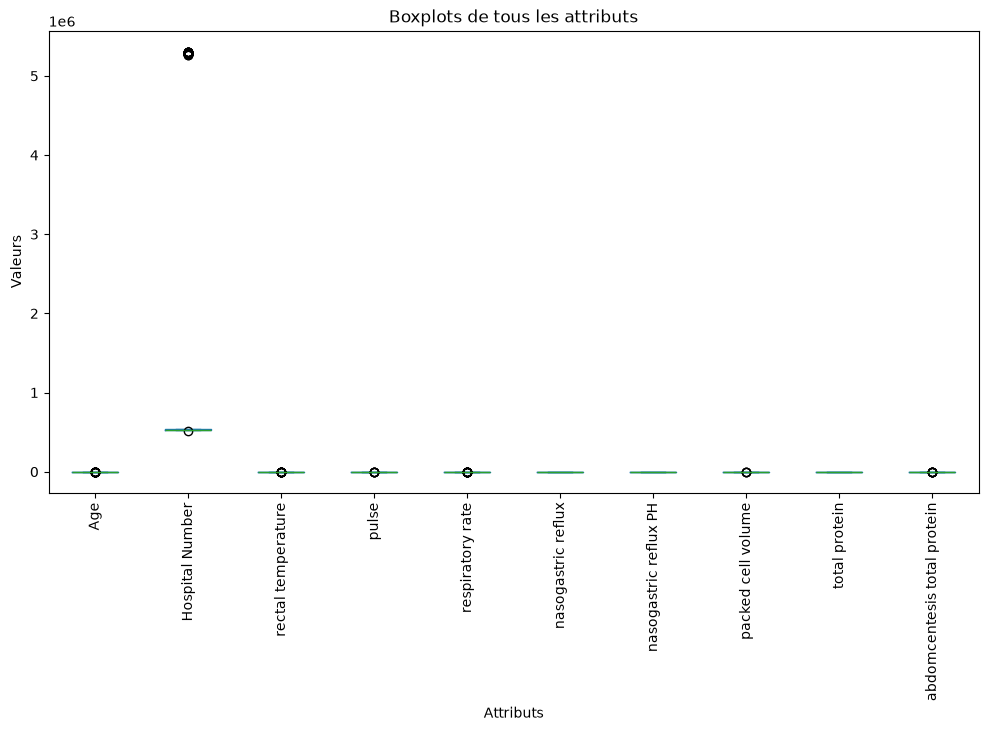

In [210]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

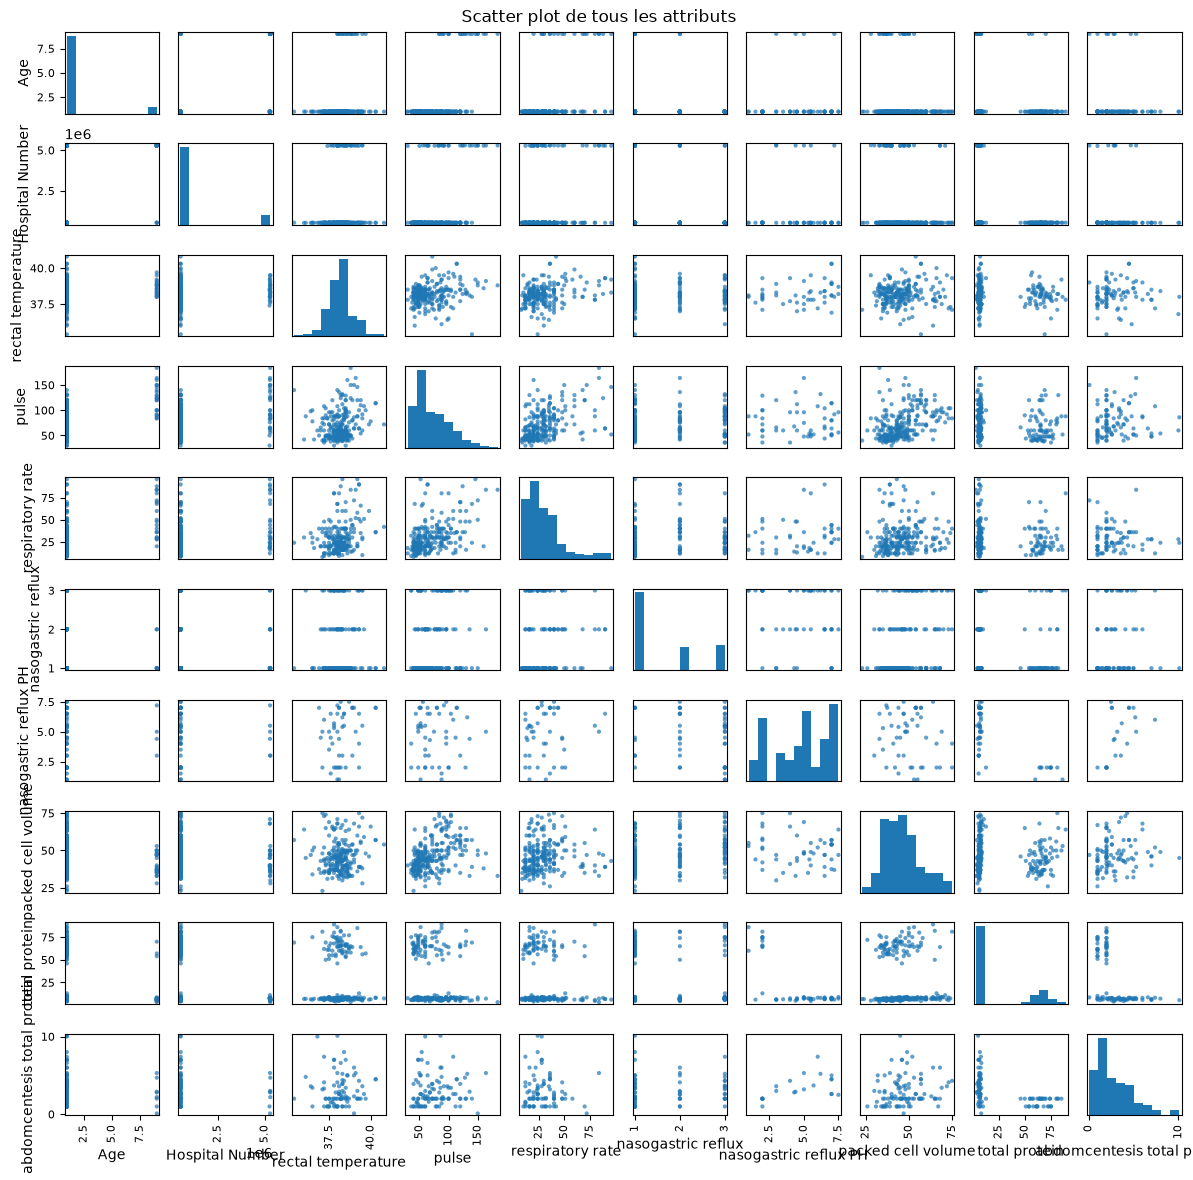

In [211]:
scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [40]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : surgery
Mode : [1.0]

Attribut : Age
Mode : [1]
Moyenne : 1.64
Médiane : 1.0

Attribut : Hospital Number
Mode : [527544, 527916, 528151, 528469, 528729, 528890, 528904, 528931, 528996, 529424, 529461, 529796, 530526, 530693, 532349, 5279822]
Moyenne : 1085888.8333333333
Médiane : 530305.5

Attribut : rectal temperature
Mode : [38.0]
Moyenne : 38.16791666666667
Médiane : 38.2

Attribut : pulse
Mode : [48.0]
Moyenne : 71.91304347826087
Médiane : 64.0

Attribut : respiratory rate
Mode : [20.0]
Moyenne : 30.417355371900825
Médiane : 24.5

Attribut : temperature of extremities
Mode : [3.0]

Attribut : peripheral pulse
Mode : [1.0]

Attribut : mucous membranes
Mode : [1.0]

Attribut : capillary refill time
Mode : [1.0]

Attribut : pain
Mode : [3.0]

Attribut : peristalsis
Mode : [3.0]

Attribut : abdominal distension
Mode : [1.0]

Attribut : nasogastric tube
Mode : [2.0]

Attribut : nasogastric reflux
Mode : [1.0]
Moyenne : 1.5824742268041236
Médiane : 1.0

Attribut : nasogastric

### 6. Gestion des valeurs manquantes:

- Identification:

In [38]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

['surgery', 'rectal temperature', 'pulse', 'respiratory rate', 'temperature of extremities', 'peripheral pulse', 'mucous membranes', 'capillary refill time', 'pain', 'peristalsis', 'abdominal distension', 'nasogastric tube', 'nasogastric reflux', 'nasogastric reflux PH', 'rectal examination', 'abdomen', 'packed cell volume', 'total protein', 'abdominocentesis appearance', 'abdomcentesis total protein', 'outcome']


- Remplacement

In [39]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [41]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,...,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,2.0,0.0,0.002428,0.574074,0.233766,0.227273,3.0,3.0,1.0,2.0,...,0.423077,0.059510,2.0,NaN,2.0,2,11300,0,0,2
1,1.0,0.0,0.003414,0.703704,0.376623,0.136364,3.0,1.0,4.0,1.0,...,0.519231,0.953326,2.0,0.19,3.0,2,2208,0,0,2
2,2.0,0.0,0.002477,0.537037,0.064935,0.181818,1.0,1.0,3.0,1.0,...,0.192308,0.039673,2.0,NaN,1.0,2,0,0,0,1
3,1.0,1.0,0.996821,0.685185,0.870130,0.863636,4.0,1.0,6.0,2.0,...,0.480769,0.045508,3.0,0.52,2.0,1,2208,0,0,1
4,2.0,0.0,0.002461,0.351852,0.480519,0.306818,3.0,1.0,6.0,2.0,...,0.980769,0.047841,2.0,NaN,2.0,2,4300,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,1.0,0.0,0.003219,NaN,0.584416,0.704545,4.0,1.0,4.0,2.0,...,0.615385,0.719953,2.0,NaN,3.0,2,3205,0,0,2
296,2.0,0.0,0.001927,0.333333,0.272727,0.181818,3.0,2.0,4.0,2.0,...,0.403846,NaN,3.0,0.32,3.0,1,2208,0,0,1
297,1.0,0.0,0.002279,0.388889,0.272727,0.250000,4.0,3.0,4.0,1.0,...,0.711538,0.040840,2.0,NaN,2.0,1,3205,0,0,2
298,1.0,0.0,0.002535,0.203704,0.454545,0.181818,3.0,3.0,3.0,1.0,...,0.519231,0.031505,3.0,0.33,1.0,1,2208,0,0,1


#### 7-2 Z-score :

In [40]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,...,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,2.0,-0.294884,-0.363914,0.454435,-0.206904,-0.137305,3.0,3.0,1.0,2.0,...,-0.124538,-0.585517,2.0,NaN,2.0,2,11300,0,0,2
1,1.0,-0.294884,-0.360826,1.412340,0.562901,-0.591702,3.0,1.0,4.0,1.0,...,0.356227,2.207707,2.0,-0.520502,3.0,2,2208,0,0,2
2,2.0,-0.294884,-0.363762,0.180748,-1.116675,-0.364504,1.0,1.0,3.0,1.0,...,-1.278373,-0.647508,2.0,NaN,1.0,2,0,0,0,1
3,1.0,3.391165,2.753002,1.275496,3.222230,3.043475,4.0,1.0,6.0,2.0,...,0.163921,-0.629275,3.0,1.164123,2.0,1,2208,0,0,1
4,2.0,-0.294884,-0.363813,-1.187688,1.122760,0.260293,3.0,1.0,6.0,2.0,...,2.663899,-0.621982,2.0,NaN,2.0,2,4300,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,1.0,-0.294884,-0.361436,NaN,1.682619,2.248280,4.0,1.0,4.0,2.0,...,0.836992,1.478406,2.0,NaN,3.0,2,3205,0,0,2
296,2.0,-0.294884,-0.365485,-1.324532,0.003043,-0.364504,3.0,2.0,4.0,2.0,...,-0.220691,NaN,3.0,0.143138,3.0,1,2208,0,0,1
297,1.0,-0.294884,-0.364382,-0.914001,0.003043,-0.023706,4.0,3.0,4.0,1.0,...,1.317757,-0.643861,2.0,NaN,2.0,1,3205,0,0,2
298,1.0,-0.294884,-0.363580,-2.282437,0.982795,-0.364504,3.0,3.0,3.0,1.0,...,0.356227,-0.673033,3.0,0.194187,1.0,1,2208,0,0,1


# Dataset **IRIS 1.arff**

###  1-lire et afficher le dataset

In [43]:
df = pd.read_csv("datasets/IRIS 1.csv")
print("Aperçu du dataset:")
display(df)

Aperçu du dataset:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,3
146,6.3,2.5,5.0,1.9,3
147,6.5,3.0,5.2,2.0,3
148,6.2,3.4,5.4,2.3,3


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [239]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 150


- Nombre des attributs (colonnes).

In [240]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 5


- Noms des attributs (colonnes).

In [241]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


- Type de chaque attribut:

In [242]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species           int64
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

**selectionner les valeurs numerique**

In [44]:
numeriques_df = df.select_dtypes(include=np.number)

**Exclure les colonnes catégorielles**

In [45]:
cat_colon= ["species"]

numeriques_df = numeriques_df.drop(
    columns=cat_colon
    )

####  En utilisant des fonctions prédéfinies.

In [199]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)


Attribut: sepal_length
Minimum: 4.3
Maximum: 7.9
Q1: 5.1
Median: 5.8
Q3: 6.4

Attribut: sepal_width
Minimum: 2.0
Maximum: 4.4
Q1: 2.8
Median: 3.0
Q3: 3.3

Attribut: petal_length
Minimum: 1.0
Maximum: 6.9
Q1: 1.6
Median: 4.35
Q3: 5.1

Attribut: petal_width
Minimum: 0.1
Maximum: 2.5
Q1: 0.3
Median: 1.3
Q3: 1.8


### 4-Visualiser la distribution des données :
- les boxplot

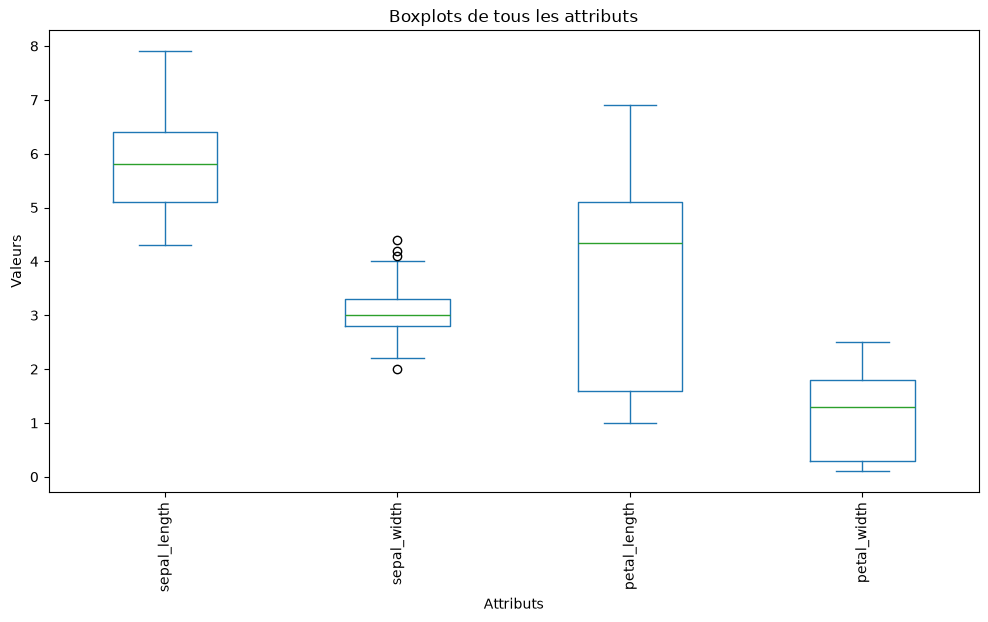

In [200]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

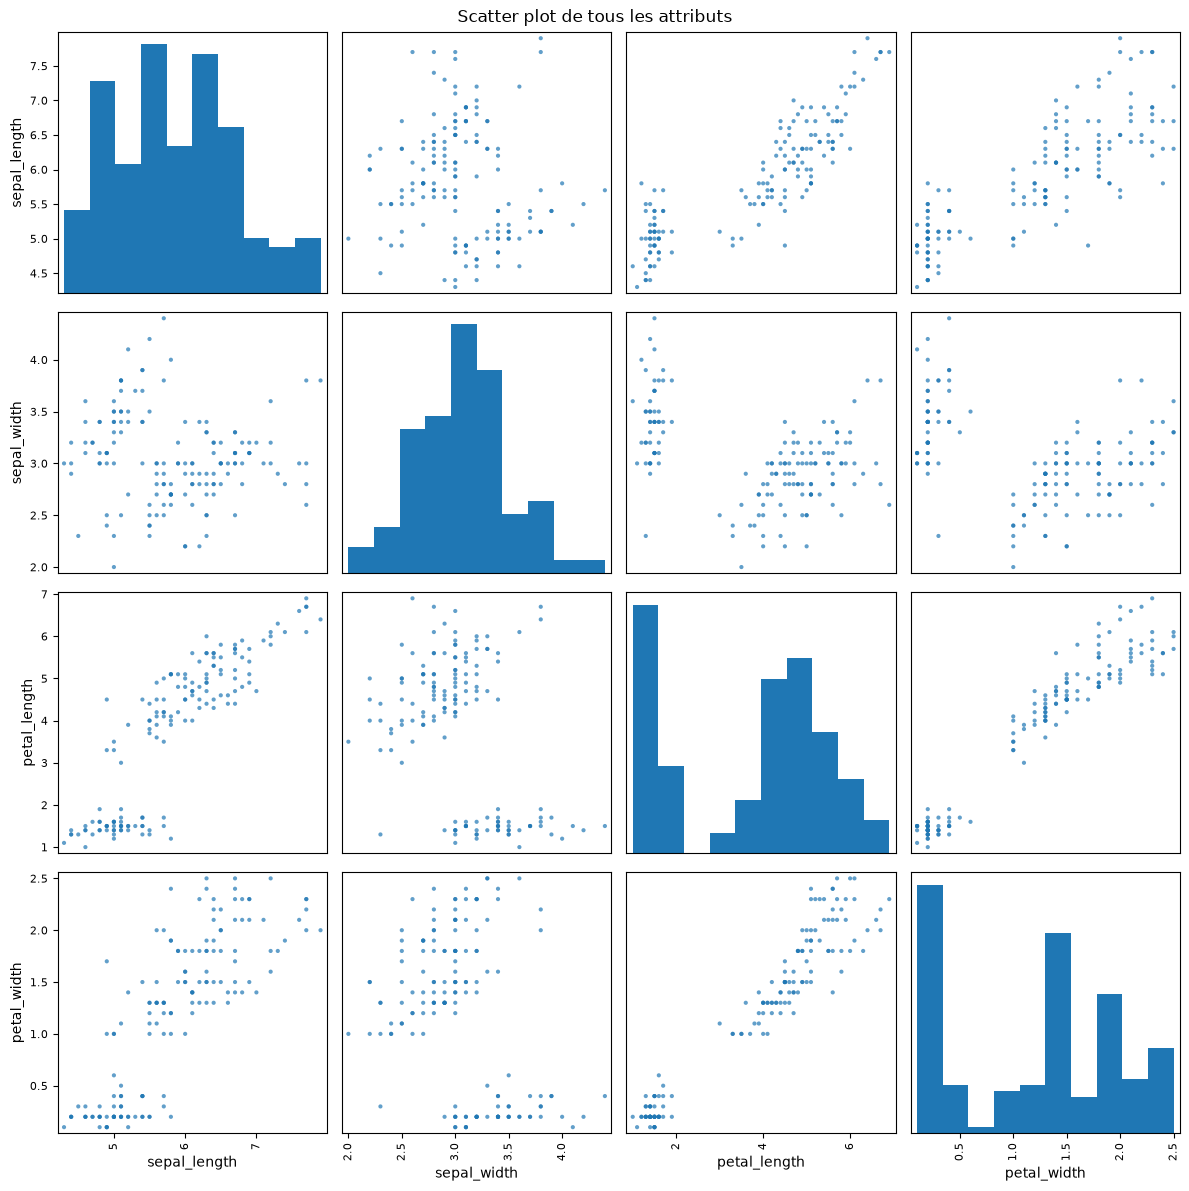

In [201]:
scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [44]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : sepal_length
Mode : [5.0]
Moyenne : 5.843333333333334
Médiane : 5.8

Attribut : sepal_width
Mode : [3.0]
Moyenne : 3.0540000000000003
Médiane : 3.0

Attribut : petal_length
Mode : [1.5]
Moyenne : 3.758666666666666
Médiane : 4.35

Attribut : petal_width
Mode : [0.2]
Moyenne : 1.1986666666666668
Médiane : 1.3

Attribut : species
Mode : [1, 2, 3]


### 6. Gestion des valeurs manquantes:

- Identification:

In [46]:
attributs_manquants = df.columns[df.isnull().any()].tolist()

print(attributs_manquants)

[]


- Remplacement

In [197]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [49]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,sepal_length,sepal_width,petal_length,petal_width,species
0,0.222222,0.625000,0.067797,0.041667,1
1,0.166667,0.416667,0.067797,0.041667,1
2,0.111111,0.500000,0.050847,0.041667,1
3,0.083333,0.458333,0.084746,0.041667,1
4,0.194444,0.666667,0.067797,0.041667,1
...,...,...,...,...,...
145,0.666667,0.416667,0.711864,0.916667,3
146,0.555556,0.208333,0.677966,0.750000,3
147,0.611111,0.416667,0.711864,0.791667,3
148,0.527778,0.583333,0.745763,0.916667,3


#### 7-2 Z-score :

In [48]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,sepal_length,sepal_width,petal_length,petal_width,species
0,-0.900681,1.032057,-1.341272,-1.312977,1
1,-1.143017,-0.124958,-1.341272,-1.312977,1
2,-1.385353,0.337848,-1.398138,-1.312977,1
3,-1.506521,0.106445,-1.284407,-1.312977,1
4,-1.021849,1.263460,-1.341272,-1.312977,1
...,...,...,...,...,...
145,1.038005,-0.124958,0.819624,1.447956,3
146,0.553333,-1.281972,0.705893,0.922064,3
147,0.795669,-0.124958,0.819624,1.053537,3
148,0.432165,0.800654,0.933356,1.447956,3


# Dataset **hypothyroid.arff**

###  1-lire et afficher le dataset

In [6]:

data, meta= arff.loadarff("datasets/hypothyroid.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,68.0,F,f,f,f,f,f,f,f,f,...,t,124.0,t,1.08,t,114.0,f,NaN,SVI,negative
3769,74.0,F,f,f,f,f,f,f,f,f,...,t,112.0,t,1.07,t,105.0,f,NaN,other,negative
3770,72.0,M,f,f,f,f,f,f,f,f,...,t,82.0,t,0.94,t,87.0,f,NaN,SVI,negative


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):


In [140]:
print("Nombre d'instances :", df.shape[0])


Nombre d'instances : 3772



- Nombre des attributs (colonnes).

In [273]:

print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 30


- Noms des attributs (colonnes).

In [274]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH measured', 'TSH', 'T3 measured', 'T3', 'TT4 measured', 'TT4', 'T4U measured', 'T4U', 'FTI measured', 'FTI', 'TBG measured', 'TBG', 'referral source', 'Class']


- Type de chaque attribut:

In [275]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
age                          float64
sex                              str
on thyroxine                     str
query on thyroxine               str
on antithyroid medication        str
sick                             str
pregnant                         str
thyroid surgery                  str
I131 treatment                   str
query hypothyroid                str
query hyperthyroid               str
lithium                          str
goitre                           str
tumor                            str
hypopituitary                    str
psych                            str
TSH measured                     str
TSH                          float64
T3 measured                      str
T3                           float64
TT4 measured                     str
TT4                          float64
T4U measured                     str
T4U                          float64
FTI measured                     str
FTI                          float64
TBG measured    

### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :
il faut premierement selectionner les valeurs numerique du dataset afin de calculer les 5 nombres clés

In [7]:
numeriques_df = df.select_dtypes(include=np.number)

**Remarque:** Dans cette dataset on a l'attribut TBG qui n'a pas de valeurs ( toujours nan ) donc on doit l'exclure car on ne peut pas trouver ses 5 valeurs clés.

In [8]:
cln_vides = df.columns[df.isnull().all()].tolist()

df_num_sanstbg = df.drop(columns=cln_vides)

#### En utilisant des fonctions predefinies

In [9]:
# Selectionner les attributs numériques
numeriques_df = df.select_dtypes(include=np.number)

# Identifier les colonnes entierement vides
cln_vides = df.columns[df.isnull().all()].tolist()

# Supprimer les colonnes entierement vides des attributs numériques
df_num_sanstbg = numeriques_df.drop(columns=cln_vides)

# Parcourir les attributs numeriques
for col in df_num_sanstbg.columns:

    values = df_num_sanstbg[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut : {col}")
    print("Minimum :", minimum)
    print("Maximum :", maximum)
    print("Q1 :", Q1)
    print("Médiane :", median)
    print("Q3 :", Q3)


Attribut : age
Minimum : 1.0
Maximum : 455.0
Q1 : 36.0
Médiane : 54.0
Q3 : 67.0

Attribut : TSH
Minimum : 0.005
Maximum : 530.0
Q1 : 0.5
Médiane : 1.4
Q3 : 2.7

Attribut : T3
Minimum : 0.05
Maximum : 10.6
Q1 : 1.6
Médiane : 2.0
Q3 : 2.4

Attribut : TT4
Minimum : 2.0
Maximum : 430.0
Q1 : 88.0
Médiane : 103.0
Q3 : 124.0

Attribut : T4U
Minimum : 0.25
Maximum : 2.32
Q1 : 0.88
Médiane : 0.98
Q3 : 1.08

Attribut : FTI
Minimum : 2.0
Maximum : 395.0
Q1 : 93.0
Médiane : 107.0
Q3 : 124.0


### 4-Visualiser la distribution des données :





- les boxplot

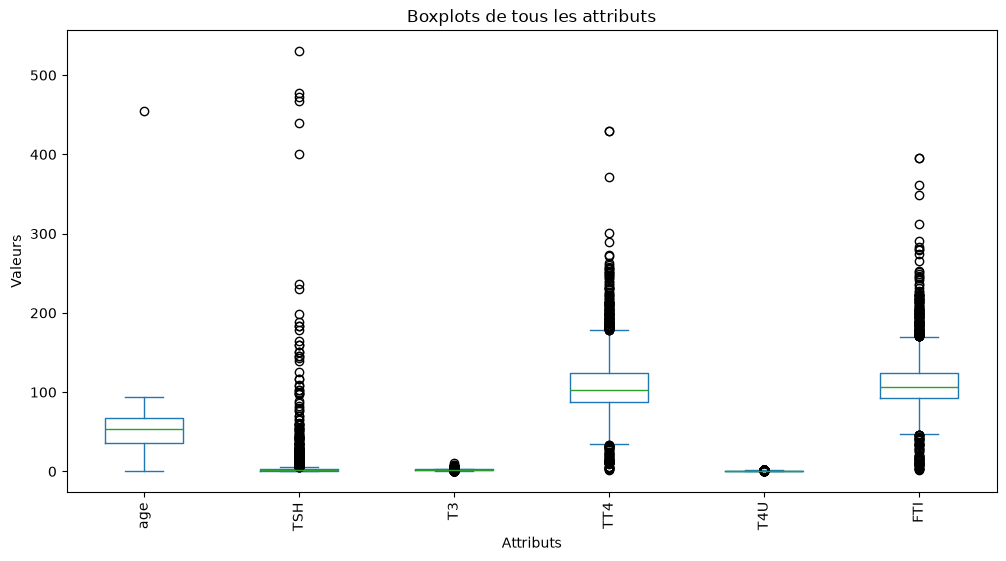

In [16]:

df_num_sanstbg.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

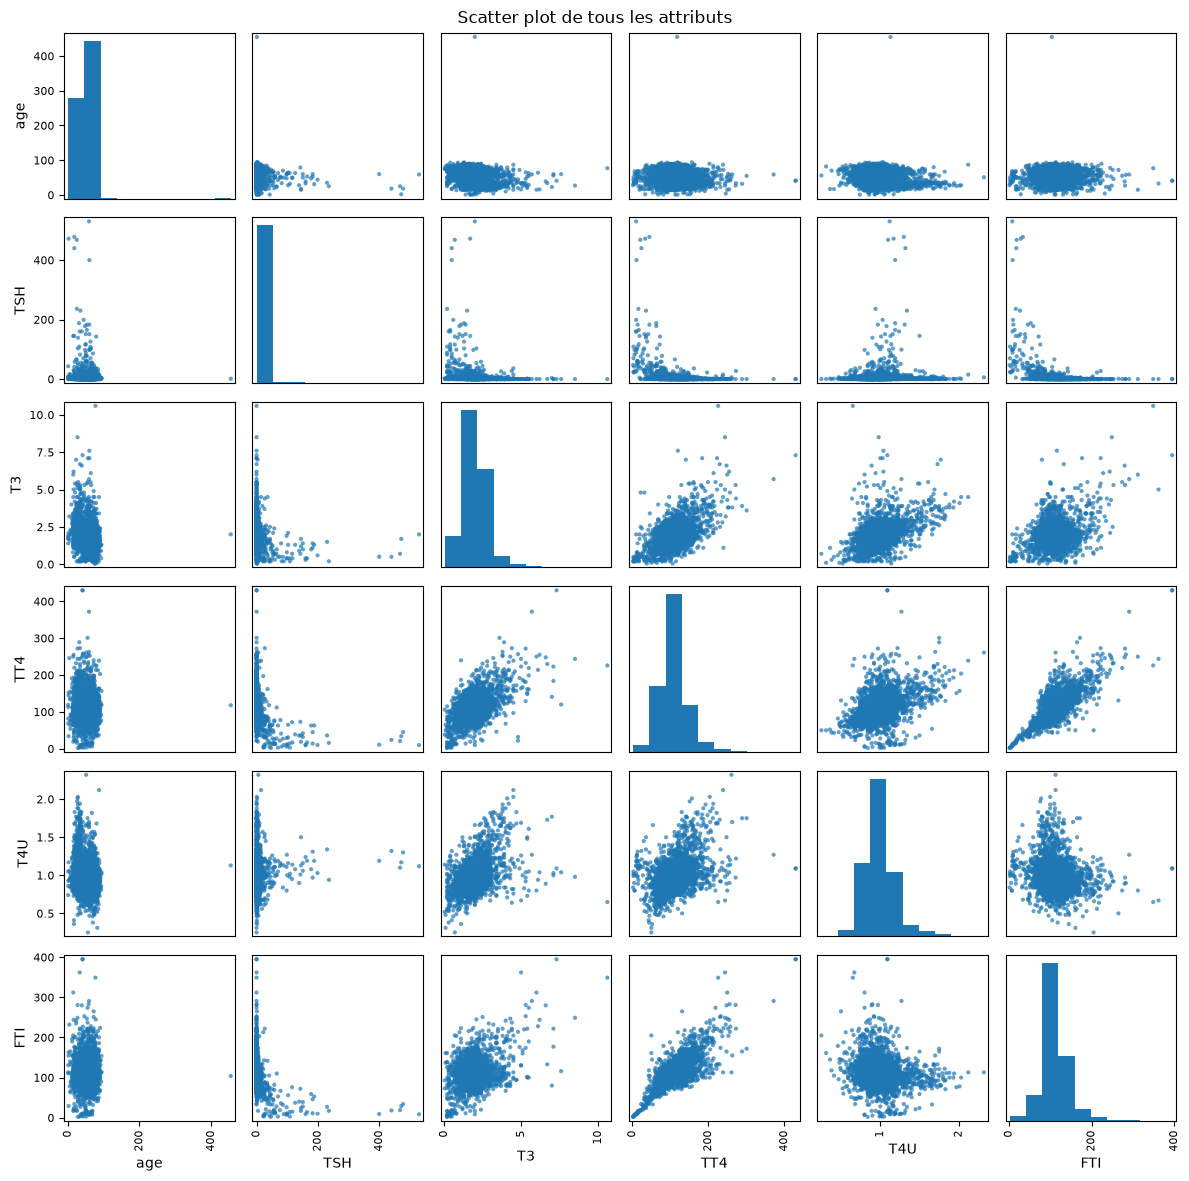

In [17]:

scatter_matrix(
   df_num_sanstbg,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [11]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    if col in cln_vides:
        continue
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : age
Mode : [59.0]
Moyenne : 51.73587907716786
Médiane : 54.0

Attribut : sex
Mode : ['F']

Attribut : on thyroxine
Mode : ['f']

Attribut : query on thyroxine
Mode : ['f']

Attribut : on antithyroid medication
Mode : ['f']

Attribut : sick
Mode : ['f']

Attribut : pregnant
Mode : ['f']

Attribut : thyroid surgery
Mode : ['f']

Attribut : I131 treatment
Mode : ['f']

Attribut : query hypothyroid
Mode : ['f']

Attribut : query hyperthyroid
Mode : ['f']

Attribut : lithium
Mode : ['f']

Attribut : goitre
Mode : ['f']

Attribut : tumor
Mode : ['f']

Attribut : hypopituitary
Mode : ['f']

Attribut : psych
Mode : ['f']

Attribut : TSH measured
Mode : ['t']

Attribut : TSH
Mode : [0.2]
Moyenne : 5.086766088745224
Médiane : 1.4

Attribut : T3 measured
Mode : ['t']

Attribut : T3
Mode : [2.0]
Moyenne : 2.0134998334998335
Médiane : 2.0

Attribut : TT4 measured
Mode : ['t']

Attribut : TT4
Mode : [101.0]
Moyenne : 108.31934481784808
Médiane : 103.0

Attribut : T4U measured
Mode : ['t'

### 6. Gestion des valeurs manquantes:

- Identification:

In [12]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'TBG']


- Remplacement

**Remarque:** l'attribut TBG contient seulement des valeurs nan donc on ne peut pas remplacer ses  valeurs avec moyenne ou mediane.

In [13]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


['TBG']


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [15]:
# Creer le normaliseur
scaler = MinMaxScaler()


# Normaliser les donnees
df[df_num_sanstbg.columns] = scaler.fit_transform(df_num_sanstbg)


display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,0.088106,F,f,f,f,f,f,f,f,f,...,t,0.287383,t,0.429952,t,0.272265,f,NaN,SVHC,negative
1,0.048458,F,f,f,f,f,f,f,f,f,...,t,0.233645,f,NaN,f,NaN,f,NaN,other,negative
2,0.099119,M,f,f,f,f,f,f,f,f,...,t,0.250000,t,0.318841,t,0.300254,f,NaN,other,negative
3,0.151982,F,t,f,f,f,f,f,f,f,...,t,0.404206,f,NaN,f,NaN,f,NaN,other,negative
4,0.151982,F,f,f,f,f,f,f,f,f,...,t,0.137850,t,0.299517,t,0.173028,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,0.063877,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,0.147577,F,f,f,f,f,f,f,f,f,...,t,0.285047,t,0.400966,t,0.284987,f,NaN,SVI,negative
3769,0.160793,F,f,f,f,f,f,f,f,f,...,t,0.257009,t,0.396135,t,0.262087,f,NaN,other,negative
3770,0.156388,M,f,f,f,f,f,f,f,f,...,t,0.186916,t,0.333333,t,0.216285,f,NaN,SVI,negative


#### 7-2 Z-score :

In [16]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[df_num_sanstbg.columns] = scaler.fit_transform(df_num_sanstbg)

# Afficher le resultat
display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,-0.534594,F,f,f,f,f,f,f,f,f,...,t,0.468568,t,0.741961,t,-0.044421,f,NaN,SVHC,negative
1,-1.430906,F,f,f,f,f,f,f,f,f,...,t,-0.177514,f,NaN,f,NaN,f,NaN,other,negative
2,-0.285619,M,f,f,f,f,f,f,f,f,...,t,0.019120,t,-0.434940,t,0.288058,f,NaN,other,negative
3,0.909464,F,t,f,f,f,f,f,f,f,...,t,1.873093,f,NaN,f,NaN,f,NaN,other,negative
4,0.909464,F,f,f,f,f,f,f,f,f,...,t,-1.329224,t,-0.639619,t,-1.223209,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,-1.082340,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,0.809874,F,f,f,f,f,f,f,f,f,...,t,0.440477,t,0.434943,t,0.106706,f,NaN,SVI,negative
3769,1.108644,F,f,f,f,f,f,f,f,f,...,t,0.103391,t,0.383774,t,-0.165322,f,NaN,other,negative
3770,1.009054,M,f,f,f,f,f,f,f,f,...,t,-0.739324,t,-0.281431,t,-0.709378,f,NaN,SVI,negative


# Dataset **lymph.arff**

###  1-lire et afficher le dataset

In [56]:

data, meta= arff.loadarff("datasets/lymph.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,lymphatics,block_of_affere,bl_of_lymph_c,bl_of_lymph_s,by_pass,extravasates,regeneration_of,early_uptake_in,lym_nodes_dimin,lym_nodes_enlar,changes_in_lym,defect_in_node,changes_in_node,changes_in_stru,special_forms,dislocation_of,exclusion_of_no,no_of_nodes_in,class
0,arched,yes,no,no,no,no,no,yes,1.0,4.0,round,lac_central,lacunar,stripped,vesicles,yes,yes,5.0,malign_lymph
1,displaced,yes,no,no,yes,yes,no,yes,1.0,3.0,round,lac_central,lacunar,diluted,vesicles,yes,yes,3.0,malign_lymph
2,deformed,no,no,no,yes,yes,yes,no,3.0,1.0,bean,lacunar,no,diluted,vesicles,no,no,7.0,fibrosis
3,arched,no,no,no,no,yes,no,yes,1.0,2.0,oval,lac_margin,lac_margin,drop_like,vesicles,no,yes,1.0,malign_lymph
4,arched,no,no,no,no,no,no,no,1.0,2.0,round,lac_margin,lac_margin,faint,vesicles,no,no,1.0,metastases
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,displaced,no,no,no,no,no,no,yes,1.0,3.0,round,lacunar,lacunar,coarse,chalices,yes,yes,2.0,metastases
144,deformed,no,no,no,no,yes,no,yes,1.0,4.0,round,lac_central,lacunar,coarse,vesicles,yes,yes,6.0,malign_lymph
145,deformed,yes,no,no,yes,yes,no,yes,1.0,2.0,oval,lac_central,lac_margin,diluted,chalices,yes,yes,4.0,malign_lymph
146,deformed,yes,no,no,no,no,no,yes,1.0,3.0,oval,lacunar,lac_central,faint,vesicles,yes,yes,3.0,malign_lymph


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):

In [113]:
print("Nombre d'instances :", df.shape[0])

Nombre d'instances : 148


- Nombre des attributs (colonnes).

In [114]:
print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 19


- Noms des attributs (colonnes).

In [115]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['lymphatics', 'block_of_affere', 'bl_of_lymph_c', 'bl_of_lymph_s', 'by_pass', 'extravasates', 'regeneration_of', 'early_uptake_in', 'lym_nodes_dimin', 'lym_nodes_enlar', 'changes_in_lym', 'defect_in_node', 'changes_in_node', 'changes_in_stru', 'special_forms', 'dislocation_of', 'exclusion_of_no', 'no_of_nodes_in', 'class']


- Type de chaque attribut:

In [116]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
lymphatics             str
block_of_affere        str
bl_of_lymph_c          str
bl_of_lymph_s          str
by_pass                str
extravasates           str
regeneration_of        str
early_uptake_in        str
lym_nodes_dimin    float64
lym_nodes_enlar    float64
changes_in_lym         str
defect_in_node         str
changes_in_node        str
changes_in_stru        str
special_forms          str
dislocation_of         str
exclusion_of_no        str
no_of_nodes_in     float64
class                  str
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

il faut premierement selectionner les valeurs numerique du dataset afin de calculer les 5 nombres clés

In [57]:
numeriques_df = df.select_dtypes(include=np.number)

#### En utilisant des fonctions prédéfinies

In [153]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)


Attribut: lym_nodes_dimin
Minimum: 1.0
Maximum: 3.0
Q1: 1.0
Median: 1.0
Q3: 1.0

Attribut: lym_nodes_enlar
Minimum: 1.0
Maximum: 4.0
Q1: 2.0
Median: 2.0
Q3: 3.0

Attribut: no_of_nodes_in
Minimum: 1.0
Maximum: 8.0
Q1: 1.0
Median: 2.0
Q3: 3.0


### 4-Visualiser la distribution des données :
- les boxplot

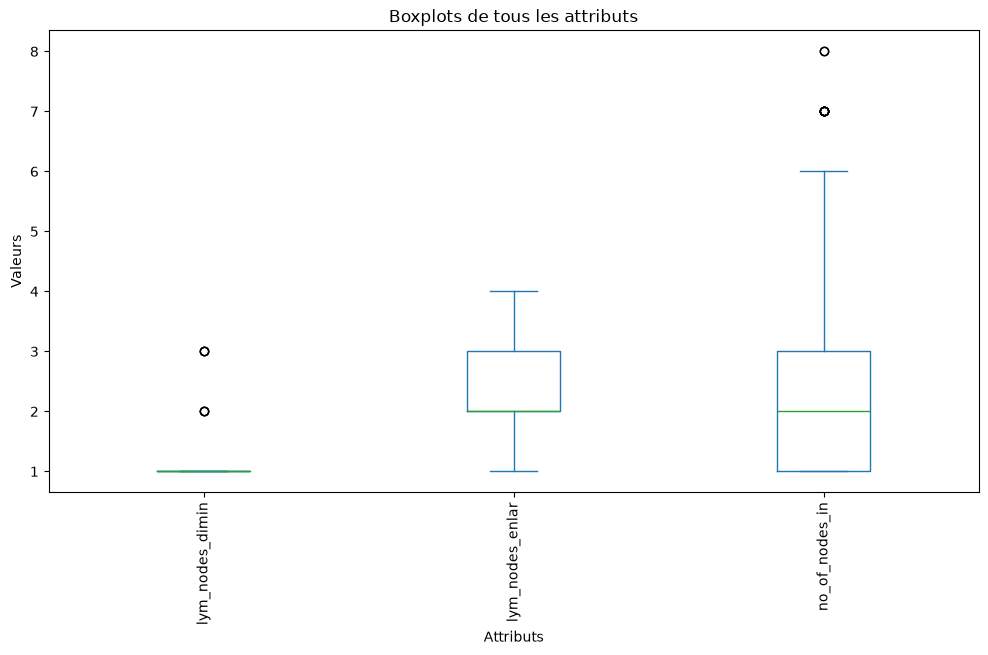

In [154]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

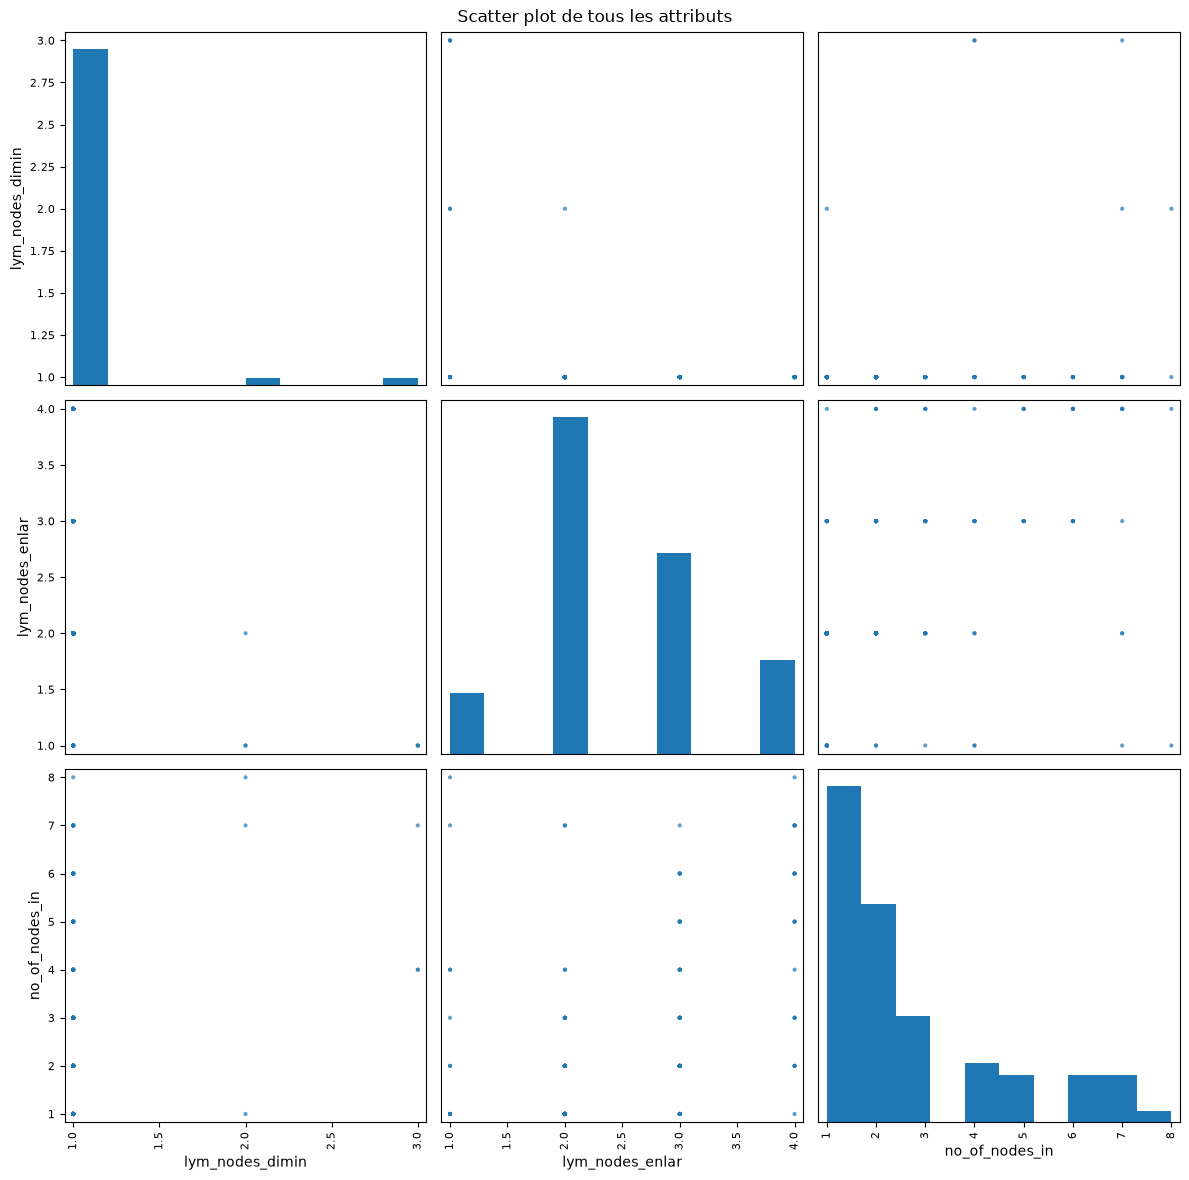

In [155]:

scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [147]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : lymphatics
Mode : ['arched']

Attribut : block_of_affere
Mode : ['yes']

Attribut : bl_of_lymph_c
Mode : ['no']

Attribut : bl_of_lymph_s
Mode : ['no']

Attribut : by_pass
Mode : ['no']

Attribut : extravasates
Mode : ['yes']

Attribut : regeneration_of
Mode : ['no']

Attribut : early_uptake_in
Mode : ['yes']

Attribut : lym_nodes_dimin
Mode : [1.0]
Moyenne : 1.0608108108108107
Médiane : 1.0

Attribut : lym_nodes_enlar
Mode : [2.0]
Moyenne : 2.472972972972973
Médiane : 2.0

Attribut : changes_in_lym
Mode : ['oval']

Attribut : defect_in_node
Mode : ['lac_central']

Attribut : changes_in_node
Mode : ['lac_margin']

Attribut : changes_in_stru
Mode : ['faint']

Attribut : special_forms
Mode : ['vesicles']

Attribut : dislocation_of
Mode : ['yes']

Attribut : exclusion_of_no
Mode : ['yes']

Attribut : no_of_nodes_in
Mode : [1.0]
Moyenne : 2.6013513513513513
Médiane : 2.0

Attribut : class
Mode : ['metastases']


### 6. Gestion des valeurs manquantes:

- Identification:

In [207]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [208]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [58]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,lymphatics,block_of_affere,bl_of_lymph_c,bl_of_lymph_s,by_pass,extravasates,regeneration_of,early_uptake_in,lym_nodes_dimin,lym_nodes_enlar,changes_in_lym,defect_in_node,changes_in_node,changes_in_stru,special_forms,dislocation_of,exclusion_of_no,no_of_nodes_in,class
0,arched,yes,no,no,no,no,no,yes,0.0,1.000000,round,lac_central,lacunar,stripped,vesicles,yes,yes,0.571429,malign_lymph
1,displaced,yes,no,no,yes,yes,no,yes,0.0,0.666667,round,lac_central,lacunar,diluted,vesicles,yes,yes,0.285714,malign_lymph
2,deformed,no,no,no,yes,yes,yes,no,1.0,0.000000,bean,lacunar,no,diluted,vesicles,no,no,0.857143,fibrosis
3,arched,no,no,no,no,yes,no,yes,0.0,0.333333,oval,lac_margin,lac_margin,drop_like,vesicles,no,yes,0.000000,malign_lymph
4,arched,no,no,no,no,no,no,no,0.0,0.333333,round,lac_margin,lac_margin,faint,vesicles,no,no,0.000000,metastases
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,displaced,no,no,no,no,no,no,yes,0.0,0.666667,round,lacunar,lacunar,coarse,chalices,yes,yes,0.142857,metastases
144,deformed,no,no,no,no,yes,no,yes,0.0,1.000000,round,lac_central,lacunar,coarse,vesicles,yes,yes,0.714286,malign_lymph
145,deformed,yes,no,no,yes,yes,no,yes,0.0,0.333333,oval,lac_central,lac_margin,diluted,chalices,yes,yes,0.428571,malign_lymph
146,deformed,yes,no,no,no,no,no,yes,0.0,0.666667,oval,lacunar,lac_central,faint,vesicles,yes,yes,0.285714,malign_lymph


#### 7-2 Z-score :

In [59]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,lymphatics,block_of_affere,bl_of_lymph_c,bl_of_lymph_s,by_pass,extravasates,regeneration_of,early_uptake_in,lym_nodes_dimin,lym_nodes_enlar,changes_in_lym,defect_in_node,changes_in_node,changes_in_stru,special_forms,dislocation_of,exclusion_of_no,no_of_nodes_in,class
0,arched,yes,no,no,no,no,no,yes,-0.194597,1.831416,round,lac_central,lacunar,stripped,vesicles,yes,yes,1.263393,malign_lymph
1,displaced,yes,no,no,yes,yes,no,yes,-0.194597,0.632082,round,lac_central,lacunar,diluted,vesicles,yes,yes,0.209972,malign_lymph
2,deformed,no,no,no,yes,yes,yes,no,6.205496,-1.766587,bean,lacunar,no,diluted,vesicles,no,no,2.316814,fibrosis
3,arched,no,no,no,no,yes,no,yes,-0.194597,-0.567253,oval,lac_margin,lac_margin,drop_like,vesicles,no,yes,-0.843448,malign_lymph
4,arched,no,no,no,no,no,no,no,-0.194597,-0.567253,round,lac_margin,lac_margin,faint,vesicles,no,no,-0.843448,metastases
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,displaced,no,no,no,no,no,no,yes,-0.194597,0.632082,round,lacunar,lacunar,coarse,chalices,yes,yes,-0.316738,metastases
144,deformed,no,no,no,no,yes,no,yes,-0.194597,1.831416,round,lac_central,lacunar,coarse,vesicles,yes,yes,1.790104,malign_lymph
145,deformed,yes,no,no,yes,yes,no,yes,-0.194597,-0.567253,oval,lac_central,lac_margin,diluted,chalices,yes,yes,0.736683,malign_lymph
146,deformed,yes,no,no,no,no,no,yes,-0.194597,0.632082,oval,lacunar,lac_central,faint,vesicles,yes,yes,0.209972,malign_lymph


# Dataset **hepatitisequilibre.arff**

###  1-lire et afficher le dataset

In [60]:

data, meta= arff.loadarff("datasets/hepatitisequilibre.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )
df.replace("?", np.nan, inplace=True)
display(df)


,AGE,SEX,STEROID,ANTIVIRALS,FATIGUE,MALAISE,ANOREXIA,LIVER_BIG,LIVER_FIRM,SPLEEN_PALPABLE,SPIDERS,ASCITES,VARICES,BILIRUBIN,ALK_PHOSPHATE,SGOT,ALBUMIN,PROTIME,HISTOLOGY,Class
0,59.0,female,no,no,yes,yes,no,yes,yes,yes,yes,no,no,1.5,107.0,157.0,3.6,38.0,yes,DIE
1,57.0,female,yes,no,yes,yes,yes,yes,no,no,yes,yes,no,4.1,NaN,48.0,2.6,73.0,no,DIE
2,54.0,female,no,no,yes,yes,no,NaN,NaN,yes,no,yes,no,3.9,120.0,28.0,3.5,43.0,yes,DIE
3,51.0,female,no,no,yes,no,yes,yes,no,yes,yes,no,no,NaN,NaN,NaN,NaN,NaN,no,DIE
4,48.0,female,no,no,yes,yes,no,yes,yes,no,yes,yes,yes,4.8,123.0,157.0,2.7,31.0,yes,DIE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,51.0,female,no,yes,yes,yes,no,yes,no,no,no,no,no,1.0,78.0,58.0,4.6,52.0,no,LIVE
66,41.0,male,yes,yes,yes,yes,yes,yes,no,no,no,no,no,0.7,81.0,53.0,5.0,74.0,no,LIVE
67,35.0,female,yes,no,yes,no,no,yes,no,no,no,no,no,0.9,58.0,92.0,4.3,73.0,no,LIVE
68,52.0,female,no,yes,no,no,no,yes,no,no,no,no,no,0.7,75.0,55.0,4.0,21.0,no,LIVE


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):

In [89]:
print("Nombre d'instances :", df.shape[0])

Nombre d'instances : 70


- Nombre des attributs (colonnes).

In [90]:
print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 20


- Noms des attributs (colonnes).

In [91]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['AGE', 'SEX', 'STEROID', 'ANTIVIRALS', 'FATIGUE', 'MALAISE', 'ANOREXIA', 'LIVER_BIG', 'LIVER_FIRM', 'SPLEEN_PALPABLE', 'SPIDERS', 'ASCITES', 'VARICES', 'BILIRUBIN', 'ALK_PHOSPHATE', 'SGOT', 'ALBUMIN', 'PROTIME', 'HISTOLOGY', 'Class']


- Type de chaque attribut:

In [92]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
AGE                float64
SEX                    str
STEROID                str
ANTIVIRALS             str
FATIGUE                str
MALAISE                str
ANOREXIA               str
LIVER_BIG              str
LIVER_FIRM             str
SPLEEN_PALPABLE        str
SPIDERS                str
ASCITES                str
VARICES                str
BILIRUBIN          float64
ALK_PHOSPHATE      float64
SGOT               float64
ALBUMIN            float64
PROTIME            float64
HISTOLOGY              str
Class                  str
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

il faut premierement selectionner les valeurs numerique du dataset afin de calculer les 5 nombres clés

In [61]:
numeriques_df = df.select_dtypes(include=np.number)

#### En utilisant des fonctions prédéfinies

In [211]:
for col in numeriques_df.columns:
    values = numeriques_df[col].dropna()

    minimum = values.min()
    maximum = values.max()
    median = values.median()
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    print(f"\nAttribut: {col}")
    print("Minimum:", minimum)
    print("Maximum:", maximum)
    print("Q1:", Q1)
    print("Median:", median)
    print("Q3:", Q3)


Attribut: AGE
Minimum: 20.0
Maximum: 78.0
Q1: 34.0
Median: 40.5
Q3: 48.75

Attribut: BILIRUBIN
Minimum: 0.3
Maximum: 8.0
Q1: 0.7
Median: 1.0
Q3: 2.0

Attribut: ALK_PHOSPHATE
Minimum: 26.0
Maximum: 280.0
Q1: 70.0
Median: 85.0
Q3: 135.0

Attribut: SGOT
Minimum: 14.0
Maximum: 528.0
Q1: 30.5
Median: 55.0
Q3: 84.5

Attribut: ALBUMIN
Minimum: 2.1
Maximum: 5.0
Q1: 3.15
Median: 3.8
Q3: 4.074999999999999

Attribut: PROTIME
Minimum: 21.0
Maximum: 100.0
Q1: 39.0
Median: 54.0
Q3: 74.0


### 4-Visualiser la distribution des données :
- les boxplot

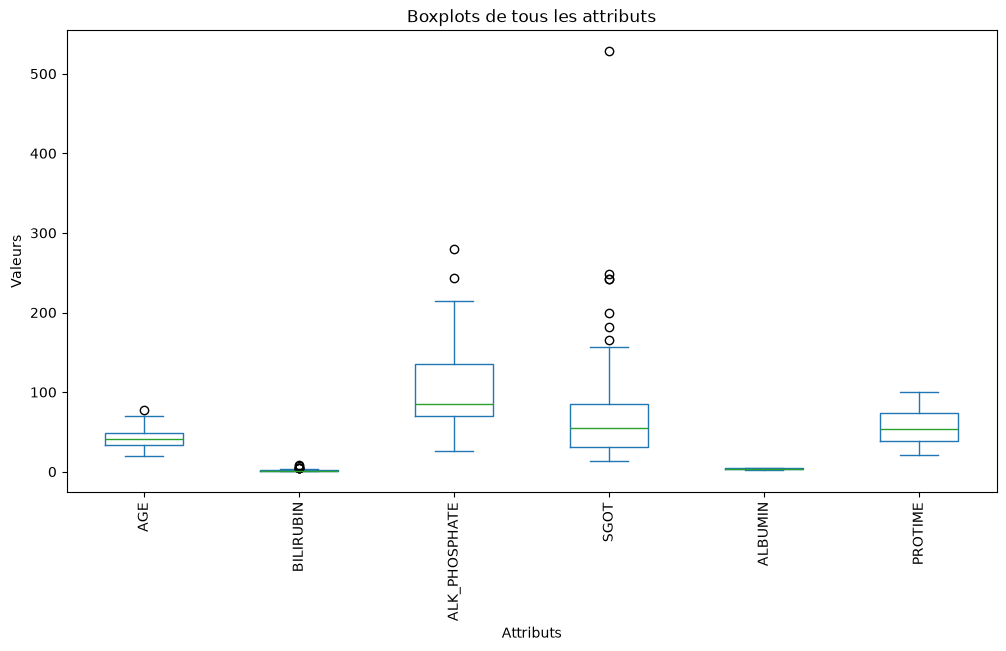

In [95]:

numeriques_df.plot(kind="box", figsize=(12, 6))

plt.title("Boxplots de tous les attributs")
plt.ylabel("Valeurs")
plt.xlabel("Attributs")
plt.xticks(rotation=90)

plt.show()

- le Scatter plot

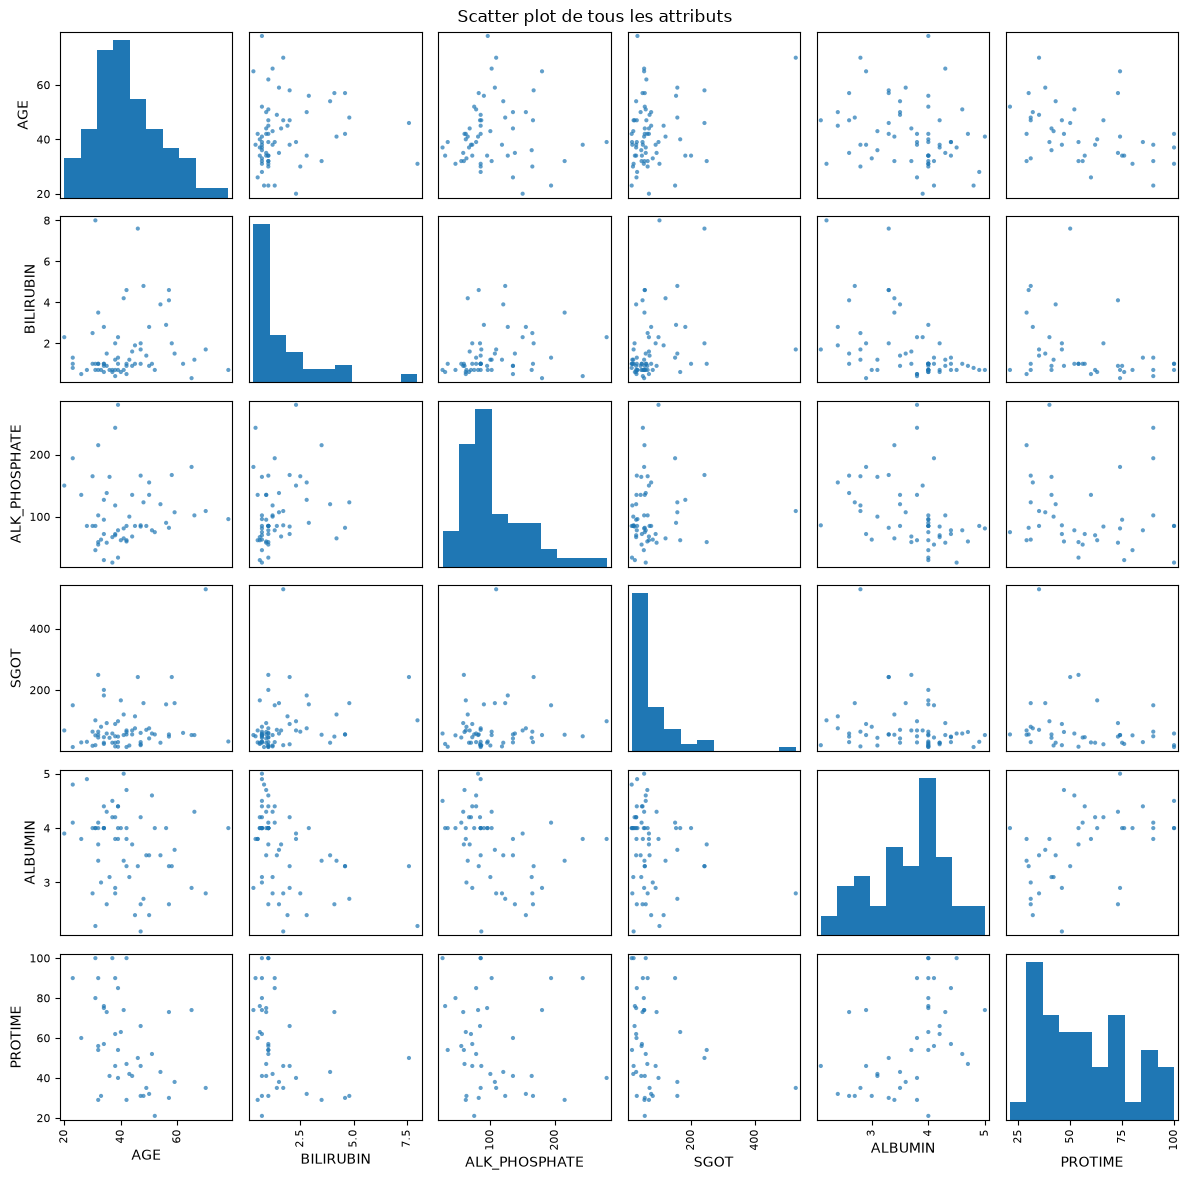

In [96]:
scatter_matrix(
    numeriques_df,
    figsize=(12, 12),
    alpha=0.7
)

plt.suptitle("Scatter plot de tous les attributs")
plt.tight_layout()
plt.show()

### 4- statistiques descriptives :

In [97]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
    if col in numeriques_df.columns:
        print("Moyenne :", values.mean())
        print("Médiane :", values.median())


Attribut : AGE
Mode : [34.0]
Moyenne : 42.2
Médiane : 40.5

Attribut : SEX
Mode : ['female']

Attribut : STEROID
Mode : ['no']

Attribut : ANTIVIRALS
Mode : ['no']

Attribut : FATIGUE
Mode : ['yes']

Attribut : MALAISE
Mode : ['no']

Attribut : ANOREXIA
Mode : ['no']

Attribut : LIVER_BIG
Mode : ['yes']

Attribut : LIVER_FIRM
Mode : ['no']

Attribut : SPLEEN_PALPABLE
Mode : ['no']

Attribut : SPIDERS
Mode : ['no']

Attribut : ASCITES
Mode : ['no']

Attribut : VARICES
Mode : ['no']

Attribut : BILIRUBIN
Mode : [1.0]
Moyenne : 1.7
Médiane : 1.0

Attribut : ALK_PHOSPHATE
Mode : [85.0]
Moyenne : 104.45614035087719
Médiane : 85.0

Attribut : SGOT
Mode : [28.0, 55.0]
Moyenne : 78.85074626865672
Médiane : 55.0

Attribut : ALBUMIN
Mode : [4.0]
Moyenne : 3.6564516129032256
Médiane : 3.8

Attribut : PROTIME
Mode : [31.0, 90.0, 100.0]
Moyenne : 56.7906976744186
Médiane : 54.0

Attribut : HISTOLOGY
Mode : ['no']

Attribut : Class
Mode : ['LIVE']


### 6. Gestion des valeurs manquantes:

- Identification:


In [212]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

['STEROID', 'LIVER_BIG', 'LIVER_FIRM', 'SPLEEN_PALPABLE', 'SPIDERS', 'ASCITES', 'VARICES', 'BILIRUBIN', 'ALK_PHOSPHATE', 'SGOT', 'ALBUMIN', 'PROTIME']


- Remplacement

In [213]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


### 7- Normaliser les données :

#### 7-1 Valeur Min-Max :


In [62]:
# Creer le normaliseur
scaler = MinMaxScaler()

# Normaliser les donnees
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)


display(df)

,AGE,SEX,STEROID,ANTIVIRALS,FATIGUE,MALAISE,ANOREXIA,LIVER_BIG,LIVER_FIRM,SPLEEN_PALPABLE,SPIDERS,ASCITES,VARICES,BILIRUBIN,ALK_PHOSPHATE,SGOT,ALBUMIN,PROTIME,HISTOLOGY,Class
0,0.672414,female,no,no,yes,yes,no,yes,yes,yes,yes,no,no,0.155844,0.318898,0.278210,0.517241,0.215190,yes,DIE
1,0.637931,female,yes,no,yes,yes,yes,yes,no,no,yes,yes,no,0.493506,NaN,0.066148,0.172414,0.658228,no,DIE
2,0.586207,female,no,no,yes,yes,no,NaN,NaN,yes,no,yes,no,0.467532,0.370079,0.027237,0.482759,0.278481,yes,DIE
3,0.534483,female,no,no,yes,no,yes,yes,no,yes,yes,no,no,NaN,NaN,NaN,NaN,NaN,no,DIE
4,0.482759,female,no,no,yes,yes,no,yes,yes,no,yes,yes,yes,0.584416,0.381890,0.278210,0.206897,0.126582,yes,DIE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,0.534483,female,no,yes,yes,yes,no,yes,no,no,no,no,no,0.090909,0.204724,0.085603,0.862069,0.392405,no,LIVE
66,0.362069,male,yes,yes,yes,yes,yes,yes,no,no,no,no,no,0.051948,0.216535,0.075875,1.000000,0.670886,no,LIVE
67,0.258621,female,yes,no,yes,no,no,yes,no,no,no,no,no,0.077922,0.125984,0.151751,0.758621,0.658228,no,LIVE
68,0.551724,female,no,yes,no,no,no,yes,no,no,no,no,no,0.051948,0.192913,0.079767,0.655172,0.000000,no,LIVE


#### 7-2 Z-score :

In [63]:
# Creer le standardiseur
scaler = StandardScaler()

# Standardiser les attributs
df[numeriques_df.columns] = scaler.fit_transform(numeriques_df)

# Afficher le resultat
display(df)

,AGE,SEX,STEROID,ANTIVIRALS,FATIGUE,MALAISE,ANOREXIA,LIVER_BIG,LIVER_FIRM,SPLEEN_PALPABLE,SPIDERS,ASCITES,VARICES,BILIRUBIN,ALK_PHOSPHATE,SGOT,ALBUMIN,PROTIME,HISTOLOGY,Class
0,1.430318,female,no,no,yes,yes,no,yes,yes,yes,yes,no,no,-0.129690,0.049737,0.988324,-0.081327,-0.844616,yes,DIE
1,1.260042,female,yes,no,yes,yes,yes,yes,no,no,yes,yes,no,1.556275,NaN,-0.390158,-1.521985,0.728586,no,DIE
2,1.004628,female,no,no,yes,yes,no,NaN,NaN,yes,no,yes,no,1.426585,0.303908,-0.643090,-0.225393,-0.619873,yes,DIE
3,0.749214,female,no,no,yes,no,yes,yes,no,yes,yes,no,no,NaN,NaN,NaN,NaN,NaN,no,DIE
4,0.493800,female,no,no,yes,yes,no,yes,yes,no,yes,yes,yes,2.010188,0.362563,0.988324,-1.377919,-1.159257,yes,DIE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,0.749214,female,no,yes,yes,yes,no,yes,no,no,no,no,no,-0.453913,-0.517262,-0.263692,1.359330,-0.215335,no,LIVE
66,-0.102166,male,yes,yes,yes,yes,yes,yes,no,no,no,no,no,-0.648448,-0.458607,-0.326925,1.935593,0.773535,no,LIVE
67,-0.612994,female,yes,no,yes,no,no,yes,no,no,no,no,no,-0.518758,-0.908295,0.166294,0.927133,0.728586,no,LIVE
68,0.834352,female,no,yes,no,no,no,yes,no,no,no,no,no,-0.648448,-0.575917,-0.301631,0.494935,-1.608743,no,LIVE


# Dataset **contact-lenses.arff**

###  1-lire et afficher le dataset

In [64]:

data, meta= arff.loadarff("datasets/contact-lenses.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,spectacle-prescrip,astigmatism,tear-prod-rate,contact-lenses
0,young,myope,no,reduced,none
1,young,myope,no,normal,soft
2,young,myope,yes,reduced,none
3,young,myope,yes,normal,hard
4,young,hypermetrope,no,reduced,none
5,young,hypermetrope,no,normal,soft
6,young,hypermetrope,yes,reduced,none
7,young,hypermetrope,yes,normal,hard
8,pre-presbyopic,myope,no,reduced,none
9,pre-presbyopic,myope,no,normal,soft


### 2-Obtenir des informations de base sur les données

- Nombre d'instances (lignes):

In [145]:
print("Nombre d'instances :", df.shape[0])

Nombre d'instances : 24


- Nombre des attributs (colonnes).

In [146]:
print("Nombre d'attributs :", df.shape[1])

Nombre d'attributs : 5


- Noms des attributs (colonnes).

In [147]:
print("Noms des attributs :")
print(df.columns.tolist())

Noms des attributs :
['age', 'spectacle-prescrip', 'astigmatism', 'tear-prod-rate', 'contact-lenses']


- Type de chaque attribut:

In [148]:
print("Types des attributs :")
print(df.dtypes)

Types des attributs :
age                   str
spectacle-prescrip    str
astigmatism           str
tear-prod-rate        str
contact-lenses        str
dtype: object


### 3-Calculer et afficher les 5 nombres clés pour chaque attribut :

**Remarque**: il n affiche pas ces 5 valeurs car il n  y a pas de donnees numeriques dans cette dataset

### 4-Visualiser la distribution des données :


**Remarque**: On ne peut pas dessiner scatter plots et boxplots car il n y a pas des valeurs numerique dans cette dataset

### 5- statistiques descriptives :

In [217]:
for col in df.columns:
    values = df[col].dropna()
    mode = values.mode()
    print(f"\nAttribut : {col}")
    print("Mode :", mode.tolist())
   


Attribut : age
Mode : ['pre-presbyopic', 'presbyopic', 'young']

Attribut : spectacle-prescrip
Mode : ['hypermetrope', 'myope']

Attribut : astigmatism
Mode : ['no', 'yes']

Attribut : tear-prod-rate
Mode : ['normal', 'reduced']

Attribut : contact-lenses
Mode : ['none']


### 6. Gestion des valeurs manquantes:

- Identification:

In [218]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


- Remplacement

In [219]:
# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:

        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

[]


### 7- Normaliser les données :

**Remarque:** toutes les attributs ne sont pas numeriques donc on ne peut pas normaliser 
